# TenderLens · S8 Anomaly & patterns

In this section I step back from the model and look at the whole picture. My CP1 feedback said "more info can be gathered", so here I try to gather that info in a clear way.

I want to answer five simple questions:

1. How big is the single-bid problem in rupees, not just in counts?
2. Which departments and work types got better or worse over time, and when do tenders pile up?
3. What happened after the bids opened: price, winners, amendments and re-posting?
4. Can a second signal, an "odd one out" detector (Isolation Forest), find unusual tenders?
5. How can an auditor combine everything into a simple "check first" list?

Two rules I follow in this section:

- Nothing here changes my S7 model. Things that happen after a tender is published (amendments, award price, winner, re-posting result) are only studied here. They are never used as model inputs, because on publishing day nobody knows them.
- My test answers (Jan-May 2023) were opened once in S7. So any test number in this section is only a description of what happened. It is not a new fair test.

| Part | Simple meaning |
|---|---|
| Train | Tenders up to Sep 2022 (2,753 tenders, 36.1% single-bid) |
| Validation | Tenders from Oct-Dec 2022 (2,270 tenders, 27.8% single-bid) |
| Test | Tenders from Jan-May 2023 (1,767 tenders, 23.8% single-bid) |
| Crore | 1 crore rupees = 1,00,00,000 rupees |

## Part A · Setup

### Step 1 · Load the tools

Here I load the libraries I need. pandas and numpy handle the tables, matplotlib draws the charts, scipy gives me two simple tests, and scikit-learn gives me the Isolation Forest. I also load my TenderLens chart style so every chart looks the same as in earlier sections.

In [1]:
import os  # to make folders and check files
import sys  # to tell Python where my style file is
import numpy as np  # number tools
import pandas as pd  # table tools
import matplotlib.pyplot as plt  # chart tools
import joblib  # to save the anomaly model to a file
from scipy.stats import mannwhitneyu  # test that compares two groups of numbers
from scipy.stats import chi2_contingency  # test that compares counts in a table
from sklearn.ensemble import IsolationForest  # the "odd one out" detector

In [2]:
sys.path.append("..")  # my style file sits one folder up
import tenderlens_style as ts  # my TenderLens colours and chart helpers
ts.use_style()  # switch on the TenderLens chart style
plt.rcParams["figure.max_open_warning"] = 0  # this section has many charts, so hide the warning

In [3]:
fig_dir = "../reports/figures"  # where I save charts
rep_dir = "../reports"  # where I save result tables
model_dir = "../models"  # where I save models for the app
os.makedirs(fig_dir, exist_ok=True)  # make the charts folder if it is missing
os.makedirs(model_dir, exist_ok=True)  # make the models folder if it is missing

### Step 2 · Load my files

Here I load four files I made in earlier sections. The clean tender table (S2) has the after-publishing facts like the number of bids, award price, winner and amendments. The clue table (S5) has the labelled tenders with their split and clues. The text clue table (S6) has the work type of each tender. The test predictions file (S7) has the risk band of every test tender.

In [4]:
date_cols = ["published_date", "last_date", "bid_opening_date"]  # columns that hold dates
tenders = pd.read_csv("../data/interim/tenders_clean.csv", parse_dates=date_cols, low_memory=False)  # clean tender table from S2
feats = pd.read_csv("../data/processed/features_split_v2.csv", parse_dates=["published_date"])  # labelled tenders with clues from S5
text = pd.read_csv("../data/processed/s6_text_clues.csv")  # work type of each tender from S6
preds = pd.read_csv("../reports/s7_test_predictions.csv")  # risk band of each test tender from S7

In [5]:
print("Clean tenders:", tenders.shape)  # all tenders, labelled or not
print("Labelled tenders with clues:", feats.shape)  # should be 6,790 rows
print("Text clues:", text.shape)  # should also be 6,790 rows
print("Test predictions:", preds.shape)  # should be 1,767 rows

Clean tenders: (39411, 39)
Labelled tenders with clues: (6790, 46)
Text clues: (6790, 7)
Test predictions: (1767, 16)


### Step 3 · Build one "who is who" table

Here I join the pieces into one table, with one row for each labelled tender. It has the split, the answer (single bid or not), department, work type, value, and the after-publishing facts. I take the answer from the clue table, so I drop the copy in the clean table to avoid two columns with the same name.

I also give the three periods friendly names and a fixed order, so every chart reads from old to new.

In [6]:
keep = ["tender_id", "split", "single_bid", "dept_main", "category", "published_date", "estimated_value", "value_missing"]  # columns I want from the clue table
base = feats[keep].copy()  # start the who-is-who table
info_cols = ["tender_id", "number_of_bids", "awarded_value", "award_ratio", "winning_supplier", "amendment_count"]  # after-publishing facts
info_cols = info_cols + ["location", "title", "title_key", "is_retender", "giant_value"]  # a few more columns I need later
info = tenders[info_cols]  # take those columns from the clean table
base = base.merge(info, on="tender_id", how="left")  # add them to each labelled tender
base = base.merge(text[["tender_id", "work_type"]], on="tender_id", how="left")  # add the work type from S6

In [7]:
order = ["train", "val", "test"]  # the three periods from old to new
period_name = {}  # friendly names for charts
period_name["train"] = "Train (to Sep 2022)"  # first period
period_name["val"] = "Validation (Oct-Dec 2022)"  # second period
period_name["test"] = "Test (Jan-May 2023)"  # third period
period_colors = [ts.BLUES[1], ts.BLUES[3], ts.BLUES[5]]  # light to dark teal, old to new
overall_rate = base["single_bid"].mean() * 100  # single-bid rate of all 6,790 labelled tenders
print("Rows:", len(base), "| repeated tender ids:", base["tender_id"].duplicated().sum())  # check one row per tender
print("Overall single-bid rate:", round(overall_rate, 1), "%")  # should be 30.1

Rows: 6790 | repeated tender ids: 0
Overall single-bid rate: 30.1 %


## Part B · How big is the problem in rupees

### Step 4 · How many bids did tenders get in each period?

Before I talk about money, I want to see the full spread of bids, not just "one or more". Here I group tenders into 1, 2, 3 and 4-or-more bids and show the share of each group inside each period. The test period is included only as a description.

In [8]:
bids = base.copy()  # copy so the main table stays clean
bids["bid_group"] = bids["number_of_bids"].clip(upper=4)  # 4 or more bids all become 4
bid_table = pd.crosstab(bids["bid_group"], bids["split"], normalize="columns")  # share of each bid group inside each period
bid_table = bid_table[order] * 100  # put periods in time order and turn shares into percent
bid_table.index = ["1 bid", "2 bids", "3 bids", "4+ bids"]  # friendly row names
bid_table = bid_table.round(1)  # one decimal place
bid_table.to_csv(rep_dir + "/s8_bid_counts.csv")  # save the table
bid_table  # show it

split,train,val,test
1 bid,36.1,27.8,23.8
2 bids,12.8,21.1,21.6
3 bids,17.8,24.0,26.5
4+ bids,33.3,27.2,28.1


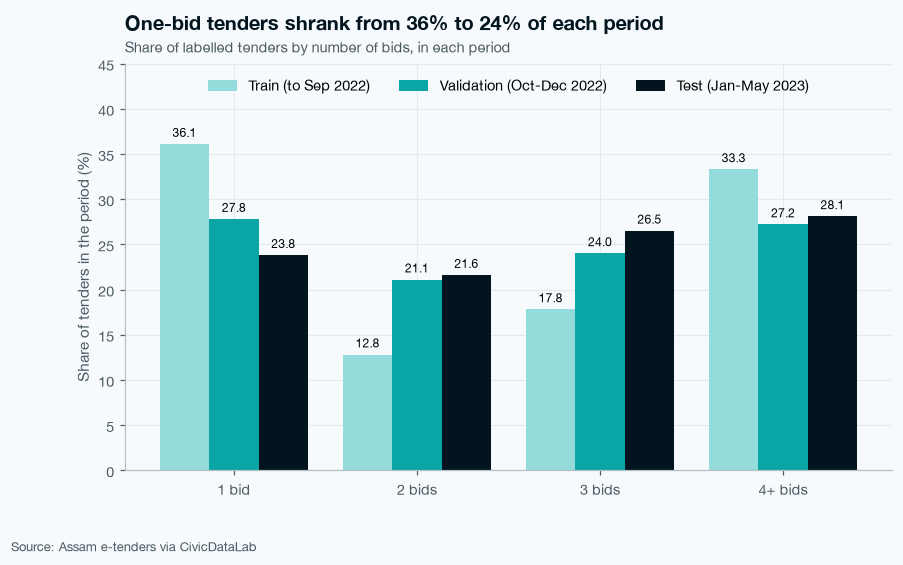

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
x = np.arange(len(bid_table))  # one position for each bid group
width = 0.27  # width of each bar
for i, p in enumerate(order):  # one set of bars for each period
    bars = ax.bar(x + (i - 1) * width, bid_table[p], width, color=period_colors[i], label=period_name[p])  # bars for this period
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)  # number on top of each bar

# labels and finish
ax.set_xticks(x)  # put ticks under each group
ax.set_xticklabels(bid_table.index)  # name each group
ax.set_ylabel("Share of tenders in the period (%)")  # y axis label
ax.set_ylim(0, 45)  # headroom under the subtitle
ax.legend(loc="upper center", ncol=3)  # legend in one row
subtitle = "Share of labelled tenders by number of bids, in each period"  # what is measured
ts.title(ax, "One-bid tenders shrank from 36% to 24% of each period", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8a_bid_counts.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 4

- The share of one-bid tenders went down in every period: 36.1% in train, 27.8% in validation and 23.8% in test.
- The space it left was filled mostly by 2 and 3 bids. Two-bid tenders went from 12.8% to 21.6%, and three-bid tenders from 17.8% to 26.5%.
- Tenders with 4 or more bids stayed around 27-33% the whole time.
- So the change after Sep 2022 is not "everything became very competitive". Many tenders simply moved from 1 bid to 2 or 3 bids.
- This is the same drift I found in S4 and S5, now seen in the full spread of bids.

### Step 5 · How much money went out with only one bidder?

Counting tenders treats a small repair and a huge road the same. Here I add up the estimated value instead. I only use tenders that have a written value. I also leave out the 2 tenders that S2 flagged as "giant values" (possible typing mistakes), so one wrong number cannot blow up the total.

I show the money in crore (1 crore = 1,00,00,000 rupees).

In [10]:
valued = base[base["estimated_value"].notna()].copy()  # keep tenders with a written value
valued = valued[valued["giant_value"] == False].copy()  # leave out the 2 giant values flagged in S2
valued["crore"] = valued["estimated_value"] / 10000000  # turn rupees into crore
valued["single_crore"] = valued["crore"] * valued["single_bid"]  # crore only when the tender got one bid, else 0
total_crore = valued["crore"].sum()  # all money in these tenders
single_crore = valued["single_crore"].sum()  # money in single-bid tenders
single_share = single_crore / total_crore * 100  # share of money with only one bidder
single_count_share = valued["single_bid"].mean() * 100  # share of tenders with only one bidder

In [11]:
print("Tenders with a value:", len(valued))  # how many tenders I used
print("Total value: Rs", round(total_crore), "crore")  # all money
print("Value in single-bid tenders: Rs", round(single_crore), "crore")  # money with no competition
print("Share of money with one bidder:", round(single_share, 1), "%")  # money view
print("Share of tenders with one bidder:", round(single_count_share, 1), "%")  # count view, to compare

Tenders with a value: 5771
Total value: Rs 40450 crore
Value in single-bid tenders: Rs 14752 crore
Share of money with one bidder: 36.5 %
Share of tenders with one bidder: 31.3 %


Now I split the same money by year. The year comes from the publishing date.

In [12]:
valued["year"] = valued["published_date"].dt.year  # year of publishing
year_table = valued.groupby("year").agg(tenders=("tender_id", "count"), total_crore=("crore", "sum"), single_crore=("single_crore", "sum"))  # money per year
year_table["single_share"] = year_table["single_crore"] / year_table["total_crore"] * 100  # share of money with one bidder
year_table = year_table.round(1)  # one decimal place
year_table.to_csv(rep_dir + "/s8_value_at_risk.csv")  # save the table
year_table  # show it

,tenders,total_crore,single_crore,single_share
year,,,,
2019,20,114.9,54.1,47.1
2020,13,17.4,4.7,26.8
2021,208,3052.5,1715.5,56.2
2022,4241,33347.7,12353.5,37.0
2023,1289,3917.6,624.0,15.9


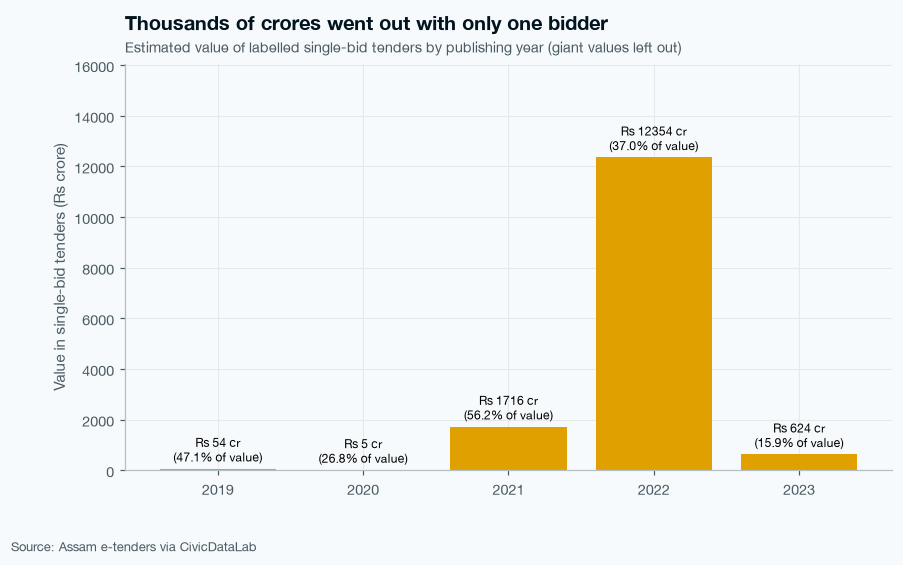

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
labels = year_table.index.astype(str)  # years as text
bars = ax.bar(labels, year_table["single_crore"], color=ts.SINGLE)  # money in single-bid tenders per year
bar_text = []  # text to write on each bar
for i in range(len(year_table)):  # one label per year
    crore_text = "Rs " + str(int(round(year_table["single_crore"].iloc[i]))) + " cr"  # money part
    share_text = "(" + str(year_table["single_share"].iloc[i]) + "% of value)"  # share part
    bar_text.append(crore_text + "\n" + share_text)  # two-line label
ax.bar_label(bars, labels=bar_text, padding=3, fontsize=8)  # write the labels

# labels and finish
ax.set_ylabel("Value in single-bid tenders (Rs crore)")  # y axis label
ax.set_ylim(0, year_table["single_crore"].max() * 1.3)  # headroom for labels
subtitle = "Estimated value of labelled single-bid tenders by publishing year (giant values left out)"  # what is measured
ts.title(ax, "Thousands of crores went out with only one bidder", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8b_value_at_risk_year.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 5

- I used 5,771 labelled tenders that have a written value (the 2 giant values from S2 were left out).
- Together they are worth about Rs 40,450 crore. About Rs 14,752 crore of that went out with only one bidder.
- That is 36.5% of the money, but only 31.3% of the tenders. So single-bid tenders are, on average, bigger works. The money view makes the problem look bigger, not smaller.
- By year, 2022 holds most of the money (Rs 12,354 crore in single-bid tenders, 37.0% of that year's value), because most of my labelled tenders are from 2022.
- 2021 had the highest share (56.2% of value with one bidder). 2023 (Jan-May) had the lowest (15.9%).
- 2019 and 2020 have very few labelled tenders (20 and 13), so I do not read much into those two bars.

### Step 6 · Which departments hold the most single-bid money?

In S3 I ranked departments by their single-bid rate. That is not the same as money. A department with a low rate but huge road works can still hold the most rupees with no competition. Here I rank departments by the money in their single-bid tenders.

In [14]:
dept_money = valued.groupby("dept_main").agg(tenders=("tender_id", "count"), total_crore=("crore", "sum"), single_crore=("single_crore", "sum"), single_rate=("single_bid", "mean"))  # money per department
dept_money["single_rate"] = dept_money["single_rate"] * 100  # rate in percent
dept_money["share_of_all_single_money"] = dept_money["single_crore"] / single_crore * 100  # this department's part of all single-bid money
dept_money = dept_money.sort_values("single_crore", ascending=False).round(1)  # biggest money first
dept_money.to_csv(rep_dir + "/s8_value_at_risk_dept.csv")  # save the table
dept_money.head(10)  # show the top 10

,tenders,total_crore,single_crore,single_rate,share_of_all_single_money
dept_main,,,,,
Assam Power Distribution Company Ltd,136,7668.3,4712.1,38.2,31.9
Public Works Building and NH Department,870,14805.9,4574.4,32.5,31.0
Public Works Roads Department-Externally Aided Project,172,4377.6,1835.7,41.9,12.4
Public Works Roads Department,1332,6956.0,1185.3,27.0,8.0
Department of Water Resources,258,2219.0,603.5,31.8,4.1
Assam Police Housing Corporation Ltd,38,665.9,406.6,44.7,2.8
Guwahati Smart City Ltd.,1,327.3,327.3,100.0,2.2
Bodoland Territorial Council,785,805.3,248.6,36.9,1.7
Department of Housing and Urban Affairs,90,494.7,168.8,38.9,1.1


In [15]:
top_money = dept_money.head(10)  # top 10 departments by single-bid money
top3_share = top_money["share_of_all_single_money"].head(3).sum()  # share held by the top 3
print("Top 3 departments hold", round(top3_share, 1), "% of all single-bid money")  # how concentrated the money is

Top 3 departments hold 75.3 % of all single-bid money


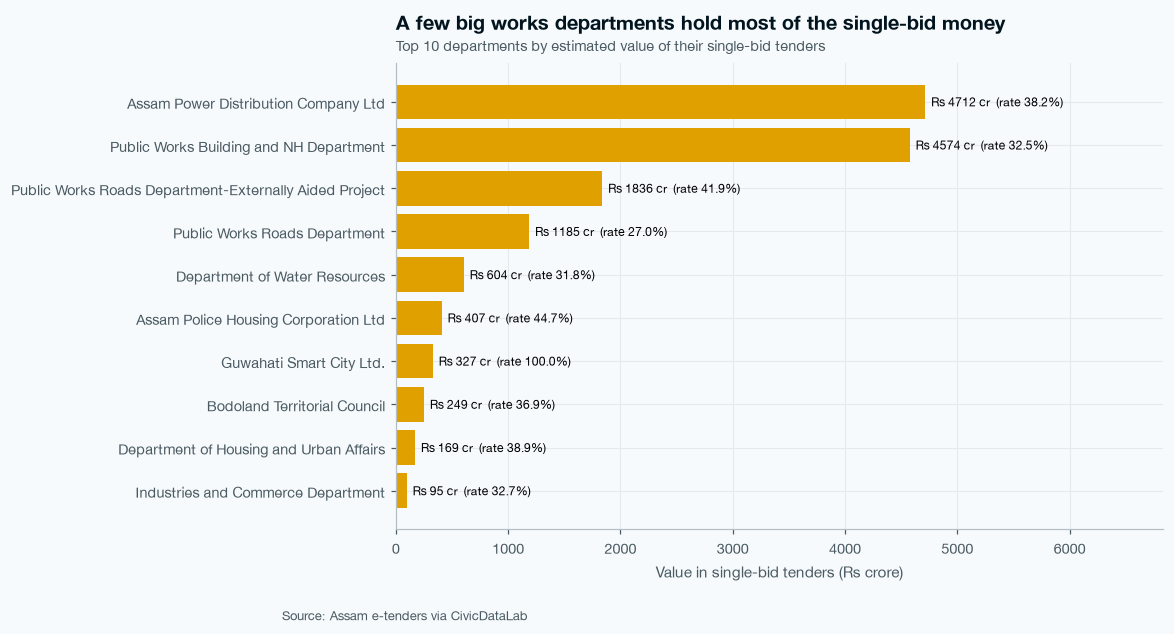

In [16]:
fig, ax = plt.subplots(figsize=(9, 5.5))  # one chart
bars = ax.barh(top_money.index, top_money["single_crore"], color=ts.SINGLE)  # one bar per department
ax.invert_yaxis()  # biggest at the top
bar_text = []  # labels for each bar
for i in range(len(top_money)):  # one label per department
    bar_text.append("Rs " + str(int(round(top_money["single_crore"].iloc[i]))) + " cr  (rate " + str(top_money["single_rate"].iloc[i]) + "%)")  # money and rate
ax.bar_label(bars, labels=bar_text, padding=4, fontsize=8)  # write labels

# labels and finish
ax.set_xlabel("Value in single-bid tenders (Rs crore)")  # x axis label
ax.set_xlim(0, top_money["single_crore"].max() * 1.45)  # room for labels
subtitle = "Top 10 departments by estimated value of their single-bid tenders"  # what is measured
ts.title(ax, "A few big works departments hold most of the single-bid money", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8c_value_at_risk_dept.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 6

- The top 3 departments hold 75.3% of all single-bid money: Assam Power Distribution Company Ltd (Rs 4,712 crore), Public Works Building and NH (Rs 4,574 crore) and PWD Roads Externally Aided Project (Rs 1,836 crore).
- This list is different from the "highest single-bid rate" list in S3. For example APDCL has a normal rate (38.2%) but very big works, so it holds the most money.
- Guwahati Smart City Ltd. shows up with Rs 327 crore from just 1 tender. One big tender can change a money ranking a lot, so I would not call it a pattern.
- For an auditor this means: if you care about rupees, a few big works departments matter far more than the many small offices.

## Part C · Who and when

### Step 7 · Which departments got better or worse after Sep 2022?

In S5 I found that patterns changed a lot after Sep 2022. Here I check it for each department. "Before" means my training period (to Sep 2022) and "After" means Oct 2022 to May 2023 (validation and test together). I only keep departments with at least 30 tenders in both, so one or two tenders cannot make a big jump.

This also helps me explain why my model missed Bodoland Territorial Council (BTC) in S7.

In [17]:
base["when"] = np.where(base["split"] == "train", "Before", "After")  # before or after Sep 2022
dept_rate = base.pivot_table(index="dept_main", columns="when", values="single_bid", aggfunc="mean") * 100  # single-bid rate before and after
dept_count = base.pivot_table(index="dept_main", columns="when", values="single_bid", aggfunc="count")  # number of tenders before and after
dept_trend = dept_rate[["Before", "After"]].copy()  # keep the two columns in order
dept_trend["n_before"] = dept_count["Before"]  # tenders before
dept_trend["n_after"] = dept_count["After"]  # tenders after

In [18]:
dept_trend = dept_trend[(dept_trend["n_before"] >= 30) & (dept_trend["n_after"] >= 30)].copy()  # only departments with enough tenders in both
dept_trend["change"] = dept_trend["After"] - dept_trend["Before"]  # change in percentage points
dept_trend = dept_trend.sort_values("change").round(1)  # biggest drop first
dept_trend.to_csv(rep_dir + "/s8_dept_trend.csv")  # save the table
dept_trend  # show it

when,Before,After,n_before,n_after,change
dept_main,,,,,
Directorate of Agriculture and Assam Seed Corporation,46.3,15.8,149.0,57.0,-30.5
Home B,34.6,5.8,81.0,69.0,-28.8
National Health Mission,34.7,7.9,225.0,353.0,-26.7
Animal Husbandry and Veterinary Department,39.0,12.7,41.0,63.0,-26.3
Industries and Commerce Department,37.0,12.3,138.0,106.0,-24.7
Public Works Roads Department,44.1,22.9,263.0,1086.0,-21.2
Assam Power Distribution Company Ltd,35.3,18.0,170.0,61.0,-17.3
Public Works Building and NH Department,37.2,28.5,417.0,459.0,-8.6
Department of Water Resources,36.8,28.2,106.0,156.0,-8.6


In [19]:
went_up = (dept_trend["change"] > 0).sum()  # departments that got worse (more single bids)
went_down = (dept_trend["change"] < 0).sum()  # departments that got better (fewer single bids)
print("Departments kept:", len(dept_trend), "| got better:", went_down, "| got worse:", went_up)  # summary
print(dept_trend.loc[dept_trend.index.str.contains("Bodoland")])  # the BTC row

Departments kept: 15 | got better: 13 | got worse: 2
when                          Before  After  n_before  n_after  change
dept_main                                                             
Bodoland Territorial Council    24.7   39.9     150.0    649.0    15.2


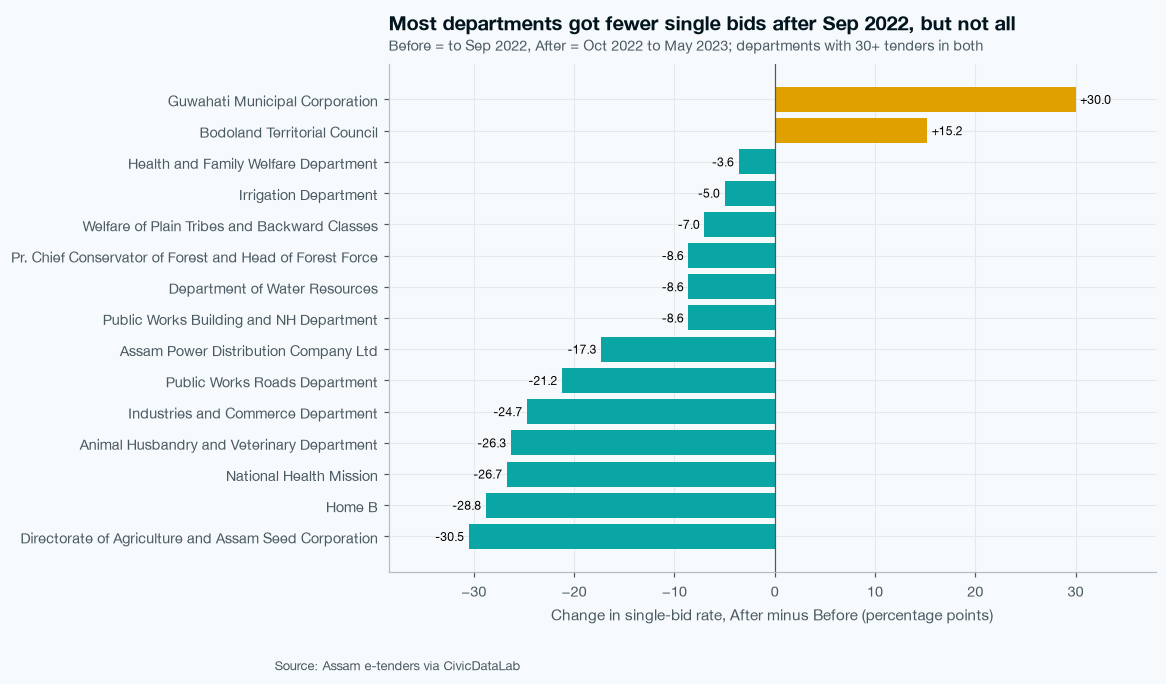

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))  # one chart
colors = np.where(dept_trend["change"] > 0, ts.SINGLE, ts.MULTI)  # amber if it got worse, teal if better
bars = ax.barh(dept_trend.index, dept_trend["change"], color=colors)  # one bar per department
ax.bar_label(bars, fmt="%+.1f", padding=3, fontsize=8)  # change on each bar
ax.axvline(0, color=ts.INK2, linewidth=0.8)  # zero line

# labels and finish
ax.set_xlabel("Change in single-bid rate, After minus Before (percentage points)")  # x axis label
xmin = dept_trend["change"].min() - 8  # room on the left
xmax = max(dept_trend["change"].max(), 0) + 8  # room on the right
ax.set_xlim(xmin, xmax)  # set the room
subtitle = "Before = to Sep 2022, After = Oct 2022 to May 2023; departments with 30+ tenders in both"  # what is measured
ts.title(ax, "Most departments got fewer single bids after Sep 2022, but not all", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8d_dept_trend.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 7

- I kept 15 departments that had at least 30 tenders both before and after Sep 2022.
- 13 of the 15 got fewer single bids after Sep 2022. The biggest drops were Directorate of Agriculture (46.3% to 15.8%), Home B (34.6% to 5.8%) and National Health Mission (34.7% to 7.9%).
- Only 2 got worse: Guwahati Municipal Corporation (1.9% to 31.9%) and Bodoland Territorial Council (24.7% to 39.9%).
- This explains my S7 miss on BTC. My model learned BTC's old, low rate from training (24.7%), but after Sep 2022 BTC became one of the worst. A clue built from the past cannot know that a department suddenly changed.
- This is another clear picture of drift: the same department can behave very differently before and after.

### Step 8 · Which work types got better or worse?

In S6 I gave every tender a simple work type from its words (roads, buildings, health and so on). Here I check the single-bid rate of each work type in each of the three periods.

In [21]:
work_rate = base.pivot_table(index="work_type", columns="split", values="single_bid", aggfunc="mean") * 100  # rate per work type and period
work_rate = work_rate[order].round(1)  # periods in time order
work_count = base.pivot_table(index="work_type", columns="split", values="single_bid", aggfunc="count")  # tenders per work type and period
work_rate["tenders"] = work_count.sum(axis=1)  # total tenders of each work type
work_rate = work_rate.sort_values("tenders", ascending=False)  # biggest work types first
work_rate.to_csv(rep_dir + "/s8_worktype_trend.csv")  # save the table
work_rate  # show it

split,train,val,test,tenders
work_type,,,,
Roads and bridges,36.4,22.4,29.1,1864
Buildings and offices,44.7,36.7,25.3,1138
Other,36.2,38.7,22.0,978
"Water, flood and irrigation",32.5,43.2,30.0,776
Health,34.7,12.8,9.4,709
Supply of goods,28.4,29.9,13.6,569
Schools and hostels,30.5,33.1,17.4,465
Power and electrical,29.7,31.6,23.3,291


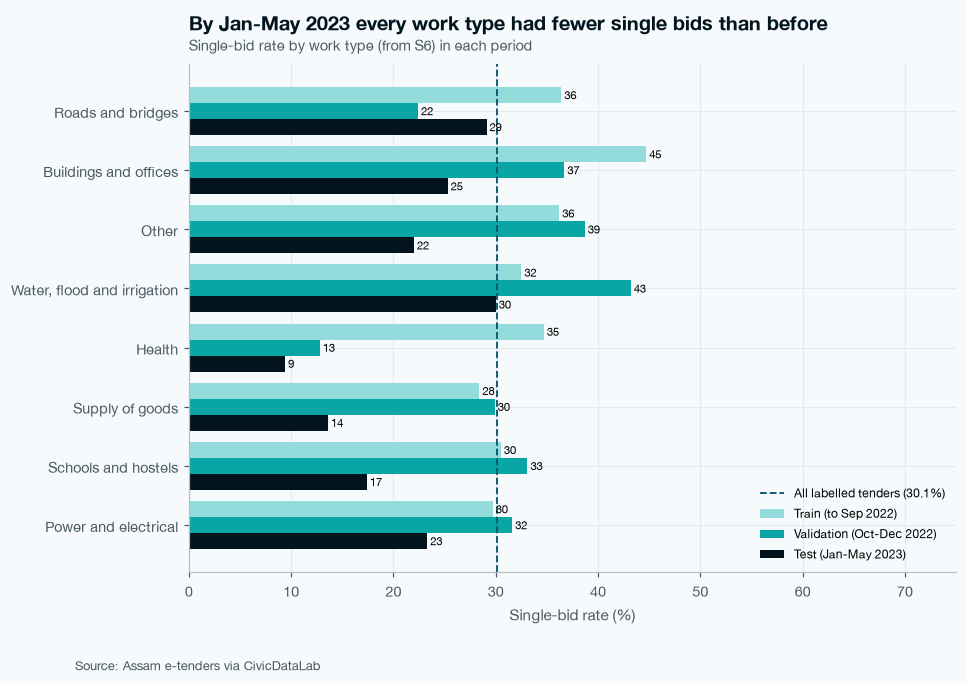

In [22]:
fig, ax = plt.subplots(figsize=(9, 6))  # one chart
y = np.arange(len(work_rate))  # one row per work type
height = 0.27  # height of each bar
for i, p in enumerate(order):  # one set of bars per period
    bars = ax.barh(y + (i - 1) * height, work_rate[p], height, color=period_colors[i], label=period_name[p])  # bars for this period
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=7.5)  # rate on each bar

# labels and finish
ax.set_yticks(y)  # one tick per work type
ax.set_yticklabels(work_rate.index)  # work type names
ax.invert_yaxis()  # biggest work type at the top
ax.axvline(overall_rate, color=ts.THIRD, linestyle="--", linewidth=1.2, label="All labelled tenders (30.1%)")  # reference line
ax.set_xlabel("Single-bid rate (%)")  # x axis label
ax.set_xlim(0, 75)  # room for labels
ax.legend(loc="lower right", fontsize=8)  # legend
subtitle = "Single-bid rate by work type (from S6) in each period"  # what is measured
ts.title(ax, "By Jan-May 2023 every work type had fewer single bids than before", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8e_worktype_trend.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 8

- By Jan-May 2023, every one of the 8 work types had a lower single-bid rate than in my training period.
- Health had the biggest fall: 34.7% in train, 12.8% in validation and 9.4% in test.
- Supply of goods and Schools and hostels also fell a lot in test (28.4% to 13.6%, and 30.5% to 17.4%).
- Validation was mixed. Water, flood and irrigation went up to 43.2% in Oct-Dec 2022 before coming down to 30.0%.
- Roads and bridges, my biggest work type (1,864 tenders), went 36.4% to 22.4% and then back up to 29.1% in test. So roads did not improve as steadily as health.

### Step 9 · Who leaves the tender value empty?

In S3 and S7 I saw that tenders with no written value get fewer single bids. SHAP in S7 said value_missing was my second strongest clue. Here I check two things. First, does that pattern hold in every period? Second, which departments and work types leave the value empty most often?

In [23]:
missing_rate = base.pivot_table(index="value_missing", columns="split", values="single_bid", aggfunc="mean") * 100  # rate with and without a value, per period
missing_rate = missing_rate[order].round(1)  # periods in time order
missing_rate.index = ["Value written", "Value empty"]  # friendly row names
missing_rate  # show it

split,train,val,test
Value written,38.1,28.5,25.6
Value empty,28.7,19.6,13.4


In [24]:
dept_missing = base.groupby("dept_main").agg(tenders=("tender_id", "count"), empty_share=("value_missing", "mean"))  # share of empty values per department
dept_missing["empty_share"] = dept_missing["empty_share"] * 100  # in percent
dept_missing = dept_missing.sort_values("tenders", ascending=False).head(12)  # 12 biggest departments
dept_missing = dept_missing.sort_values("empty_share", ascending=False).round(1)  # most empty first
work_missing = base.groupby("work_type")["value_missing"].mean() * 100  # share of empty values per work type
work_missing = work_missing.sort_values(ascending=False).round(1)  # most empty first
print(work_missing)  # show work types
dept_missing  # show departments

work_type
Supply of goods                70.1
Power and electrical           33.7
Other                          22.7
Health                         13.8
Buildings and offices           7.2
Water, flood and irrigation     5.9
Schools and hostels             5.2
Roads and bridges               2.6
Name: value_missing, dtype: float64


,tenders,empty_share
dept_main,,
Home B,150,82.7
Industries and Commerce Department,244,58.6
Assam Power Distribution Company Ltd,231,40.7
Welfare of Plain Tribes and Backward Classes,179,36.9
Directorate of Agriculture and Assam Seed Corporation,206,10.2
Guwahati Municipal Corporation,215,4.2
Public Works Roads Department-Externally Aided Project,176,2.3
Bodoland Territorial Council,799,1.8
Department of Water Resources,262,1.5


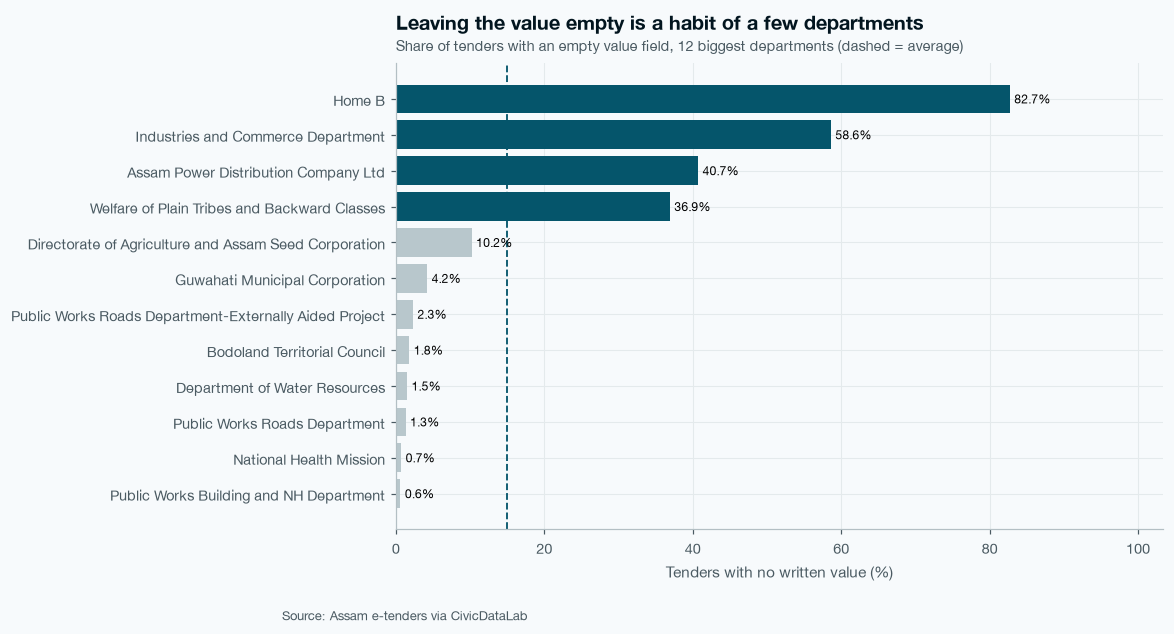

In [25]:
fig, ax = plt.subplots(figsize=(9, 5.5))  # one chart
average_empty = base["value_missing"].mean() * 100  # average share of empty values
colors = np.where(dept_missing["empty_share"] > average_empty, ts.THIRD, ts.NEUTRAL)  # dark if above average
bars = ax.barh(dept_missing.index, dept_missing["empty_share"], color=colors)  # one bar per department
ax.invert_yaxis()  # most empty at the top
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)  # share on each bar
ax.axvline(average_empty, color=ts.THIRD, linestyle="--", linewidth=1.2)  # average line

# labels and finish
ax.set_xlabel("Tenders with no written value (%)")  # x axis label
ax.set_xlim(0, dept_missing["empty_share"].max() * 1.25)  # room for labels
subtitle = "Share of tenders with an empty value field, 12 biggest departments (dashed = average)"  # what is measured
ts.title(ax, "Leaving the value empty is a habit of a few departments", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8f_value_empty_dept.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 9

- In every period, tenders with an empty value field got fewer single bids: 28.7% vs 38.1% in train, 19.6% vs 28.5% in validation and 13.4% vs 25.6% in test.
- So value_missing is one of my steadiest clues. That matches what SHAP showed in S7.
- Leaving the value empty is a habit of a few departments. Home B leaves it empty in 82.7% of tenders, Industries and Commerce in 58.6% and APDCL in 40.7%. Big works departments like PWD almost always write it (about 1%).
- By work type, Supply of goods leaves it empty most often (70.1%), and Roads and bridges almost never (2.6%).
- So "value empty" partly tells the model "this is a goods or supply tender from certain offices". Those tenders tend to attract more bidders. It is not that hiding the value magically brings more firms.

### Step 10 · The year-end rush

In S7, SHAP said months_to_fy_end (months left until the financial year ends on 31 March) was my strongest clue. Here I want to understand it with a simple calendar view. For each month of the financial year (April to March), I count the tenders and check their single-bid rate.

If tenders pile up near March and those months also look different, then the clue is mostly a calendar effect. It is not a sign of wrongdoing.

In [26]:
base["month"] = base["published_date"].dt.month  # month number, 1 = January
fy_order = [4, 5, 6, 7, 8, 9, 10, 11, 12, 1, 2, 3]  # financial year order, April first
month_names = ["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar"]  # names in the same order
month_table = base.groupby("month").agg(tenders=("tender_id", "count"), single_rate=("single_bid", "mean"))  # count and rate per month
month_table = month_table.reindex(fy_order)  # put months in financial year order
month_table["single_rate"] = (month_table["single_rate"] * 100).round(1)  # rate in percent
month_table.index = month_names  # month names instead of numbers
month_table.to_csv(rep_dir + "/s8_march_rush.csv")  # save the table
month_table  # show it

,tenders,single_rate
Apr,339,26.5
May,443,41.3
Jun,373,39.9
Jul,328,36.9
Aug,321,30.2
Sep,508,36.2
Oct,434,35.3
Nov,771,37.7
Dec,1369,20.7
Jan,684,28.7


In [27]:
last_quarter = month_table.loc[["Jan", "Feb", "Mar"], "tenders"].sum()  # tenders in Jan-Mar
last_quarter_share = last_quarter / month_table["tenders"].sum() * 100  # their share of all labelled tenders
print("Share of labelled tenders published in Jan-Mar:", round(last_quarter_share, 1), "%")  # a fair share would be 25%

Share of labelled tenders published in Jan-Mar: 28.0 %


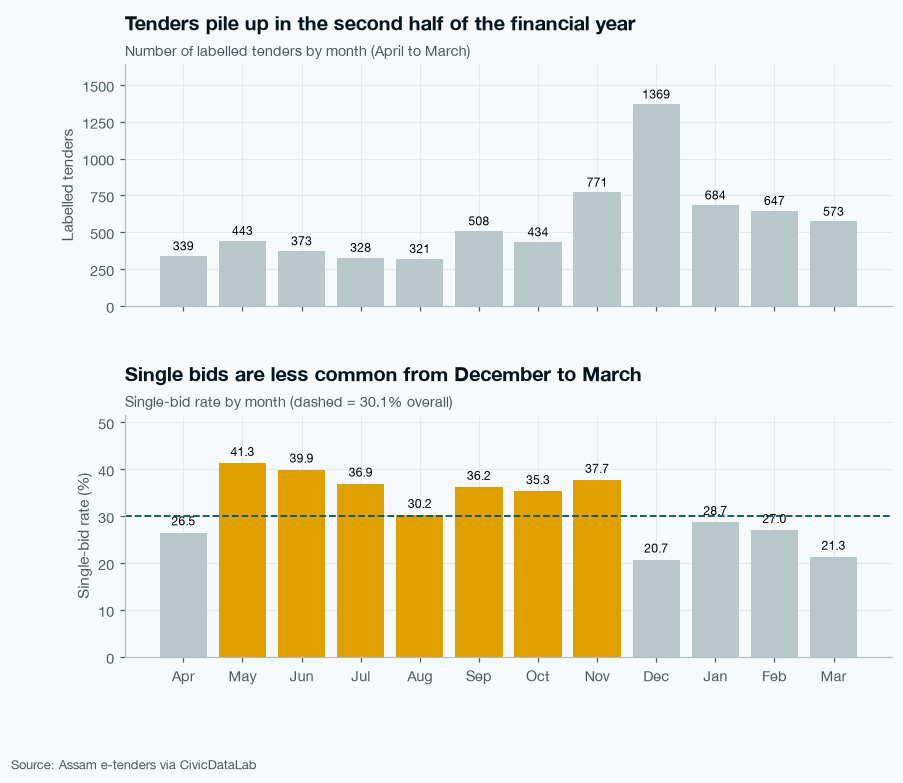

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)  # two charts, one above the other
fig.subplots_adjust(hspace=0.45)  # space between the two charts

# top chart: number of tenders
ax = axes[0]  # top chart
bars = ax.bar(month_table.index, month_table["tenders"], color=ts.NEUTRAL)  # tenders per month
ax.bar_label(bars, padding=2, fontsize=8)  # count on each bar
ax.set_ylabel("Labelled tenders")  # y axis label
ax.set_ylim(0, month_table["tenders"].max() * 1.2)  # headroom
ts.title(ax, "Tenders pile up in the second half of the financial year", subtitle="Number of labelled tenders by month (April to March)")  # finding as title

# bottom chart: single-bid rate
ax = axes[1]  # bottom chart
colors = np.where(month_table["single_rate"] > overall_rate, ts.SINGLE, ts.NEUTRAL)  # amber if above the overall rate
bars = ax.bar(month_table.index, month_table["single_rate"], color=colors)  # rate per month
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)  # rate on each bar
ax.axhline(overall_rate, color=ts.THIRD, linestyle="--", linewidth=1.2)  # overall 30.1% line
ax.set_ylabel("Single-bid rate (%)")  # y axis label
ax.set_ylim(0, month_table["single_rate"].max() * 1.25)  # headroom
ts.title(ax, "Single bids are less common from December to March", subtitle="Single-bid rate by month (dashed = 30.1% overall)")  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8g_march_rush.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 10

- Labelled tenders are not spread evenly over the year. November (771) and December (1,369) have the most. December alone is about 1 in 5 of all labelled tenders.
- Jan-Mar has 28.0% of labelled tenders, only a little above a fair 25%. So the real pile-up is in Nov-Dec, not in March itself.
- The single-bid rate is lower from December to March (20.7%, 28.7%, 27.0%, 21.3%) and higher from May to November (30-41%).
- One limit: most of my labelled Dec-Mar tenders are from Dec 2022 to Mar 2023, the newer and more competitive period. So part of this calendar pattern is really the drift over time.
- This helps me explain months_to_fy_end, my top SHAP clue: it mostly tells the model what part of the calendar a tender sits in. It is a calendar effect, not a reason why a tender gets one bid.

### Step 11 · Can I use the district?

A district view would be nice for a map. But the location column is typed by hand. The same place is written in many ways (for example "Guwahati" and "GUWAHATI"), and many rows only name a small town, an office or a factory. Here I try a fair, simple test: I look for the name of an Assam district (or its main town) inside the location text. If too many rows do not match, I will not guess.

In [29]:
district_words = ["baksa", "bajali", "barpeta", "biswanath", "bongaigaon", "cachar", "charaideo", "chirang", "darrang"]  # district names, part 1
district_words = district_words + ["dhemaji", "dhubri", "dibrugarh", "dima hasao", "goalpara", "golaghat", "hailakandi", "hojai", "jorhat"]  # part 2
district_words = district_words + ["kamrup", "karbi anglong", "karimganj", "kokrajhar", "lakhimpur", "majuli", "morigaon", "marigaon", "nagaon"]  # part 3
district_words = district_words + ["nalbari", "sivasagar", "sibsagar", "sonitpur", "tinsukia", "udalguri", "tamulpur", "guwahati", "tezpur"]  # part 4
district_words = district_words + ["silchar", "diphu", "haflong", "mangaldai", "dispur"]  # main towns that clearly point to one district
location_text = base["location"].fillna("").str.lower()  # location in small letters

In [30]:
matched = pd.Series(False, index=base.index)  # start with no match
for word in district_words:  # check one district name at a time
    matched = matched | location_text.str.contains(word, regex=False)  # mark rows that contain this name
match_share = matched.mean() * 100  # share of tenders that matched a district
print("Different location texts:", base["location"].nunique())  # how messy the column is
print("Tenders that match a district name:", round(match_share, 1), "%")  # share I could use
print(base.loc[matched == False, "location"].value_counts().head(12))  # most common texts that did not match

Different location texts: 1584
Tenders that match a district name: 64.5 %
location
KHANAPARA                             99
At Sukla FIS                          95
at Sukla FIS                          66
Assam                                 38
Rangia                                28
Duliajan                              27
APL Namrup                            27
Gossaigaon                            24
Jalukbari                             23
Medical College Hospitals of Assam    22
Sidli                                 22
Bijni                                 19
Name: count, dtype: int64


Only about two out of three tenders match a district name. The rest are small towns, offices, factories or "Assam" in general. To place them I would have to guess the district from local knowledge, and I cannot defend that. So I checked the district view, found it too messy to use, and I am leaving it out. A district map would also be biased, because the missing third is not random.

## Part D · After the bids open (study only, never model inputs)

Everything in this part happens after a tender is published: the award price, the winner, amendments and re-posting. My model can never use these facts, because they do not exist on publishing day. But they tell me why single bids matter.

### Step 12 · Does the government pay more when there is only one bidder?

The award ratio is the winning price divided by the estimated value. A ratio of 0.95 means the work was given 5% below the estimate. If competition helps, single-bid tenders should have a ratio closer to 1 (less discount).

I use the award ratio as cleaned in S2 (odd values were already removed). To check whether the gap between the groups is real or just chance, I use the Mann-Whitney test.

| Part | Simple meaning |
|---|---|
| Award ratio | Winning price ÷ estimated value |
| Median | The middle value, so a few odd tenders cannot pull it |
| Mann-Whitney test | Compares two groups of numbers without assuming a bell shape |
| p-value | Chance of seeing a gap this big if there were really no gap. Below 0.05 = probably real |

In [31]:
awarded = base[base["award_ratio"].notna()].copy()  # tenders with a clean award ratio
single_ratio = awarded.loc[awarded["single_bid"] == 1, "award_ratio"]  # ratios of single-bid tenders
multi_ratio = awarded.loc[awarded["single_bid"] == 0, "award_ratio"]  # ratios of multi-bid tenders
med_single = single_ratio.median()  # middle ratio, single bid
med_multi = multi_ratio.median()  # middle ratio, multi bid
test_result = mannwhitneyu(single_ratio, multi_ratio)  # are the two groups really different?

In [32]:
print("Tenders with an award ratio:", len(awarded), "| single:", len(single_ratio), "| multi:", len(multi_ratio))  # group sizes
print("Median award ratio, single bid:", round(med_single, 3))  # single-bid middle
print("Median award ratio, multi bid:", round(med_multi, 3))  # multi-bid middle
print("Mann-Whitney p-value:", round(test_result.pvalue, 4))  # below 0.05 means probably a real gap

Tenders with an award ratio: 2933 | single: 1481 | multi: 1452
Median award ratio, single bid: 0.961
Median award ratio, multi bid: 0.95
Mann-Whitney p-value: 0.0318


The whole-data result can hide changes over time (my S5 lesson). So I also check the medians inside each period.

In [33]:
ratio_by_period = awarded.pivot_table(index="split", columns="single_bid", values="award_ratio", aggfunc="median")  # median ratio per period and group
ratio_by_period = ratio_by_period.reindex(order).round(3)  # periods in time order
ratio_by_period.columns = ["Multi bid", "Single bid"]  # friendly names
ratio_count = awarded.groupby("split")["award_ratio"].count().reindex(order)  # how many awards in each period
ratio_by_period["awards"] = ratio_count  # add the count
ratio_rows = []  # rows for the saved table
row = {}  # whole-data row
row["what"] = "all periods"  # label
row["median_single"] = med_single  # single-bid median
row["median_multi"] = med_multi  # multi-bid median
row["p_value"] = test_result.pvalue  # test result
ratio_rows.append(row)  # keep it
pd.DataFrame(ratio_rows).to_csv(rep_dir + "/s8_award_ratio_test.csv", index=False)  # save the test result
ratio_by_period  # show it

,Multi bid,Single bid,awards
split,,,
train,0.918,0.950,1493
val,0.952,0.983,915
test,1.000,1.000,525


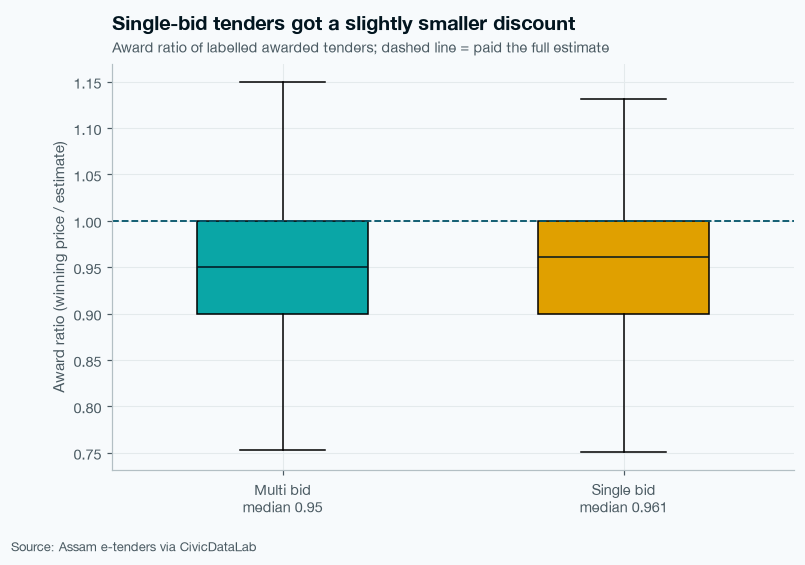

In [34]:
fig, ax = plt.subplots(figsize=(8, 4.8))  # one chart
box = ax.boxplot([multi_ratio, single_ratio], showfliers=False, patch_artist=True, widths=0.5)  # two boxes, odd points hidden
box["boxes"][0].set_facecolor(ts.MULTI)  # multi-bid box in teal
box["boxes"][1].set_facecolor(ts.SINGLE)  # single-bid box in amber
for line in box["medians"]:  # the middle line in each box
    line.set_color(ts.NAVY)  # make it dark so it shows

# labels and finish
ax.set_xticks([1, 2])  # two positions
ax.set_xticklabels(["Multi bid\nmedian " + str(round(med_multi, 3)), "Single bid\nmedian " + str(round(med_single, 3))])  # names with medians
ax.axhline(1.0, color=ts.THIRD, linestyle="--", linewidth=1.2)  # ratio 1 = paid the full estimate
ax.set_ylabel("Award ratio (winning price / estimate)")  # y axis label
subtitle = "Award ratio of labelled awarded tenders; dashed line = paid the full estimate"  # what is measured
ts.title(ax, "Single-bid tenders got a slightly smaller discount", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8h_award_ratio.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 12

- 2,933 tenders have a clean award ratio: 1,481 single-bid and 1,452 multi-bid.
- The middle award ratio is 0.961 for single-bid tenders and 0.950 for multi-bid tenders. So with one bidder the government got about 1 percentage point less discount.
- The Mann-Whitney p-value is 0.032, below 0.05, so on the whole data the gap is probably real.
- Inside each period the gap holds in train (0.950 vs 0.918) and validation (0.983 vs 0.952), but not in test, where both groups sit at 1.000.
- So the honest message is: single-bid tenders got a slightly smaller discount in 2022, but the gap is small and not seen in every period.

### Step 13 · Does more competition mean a lower price?

Step 12 compared one bid with "more than one". Here I go further and check the median award ratio for 1, 2, 3, 4 and 5-or-more bids. I also count how many awards were given at almost exactly the estimate (ratio between 0.995 and 1.005), because that tells me how often there was no discount at all.

In [35]:
awarded["bid_group"] = awarded["number_of_bids"].clip(upper=5)  # 5 or more bids all become 5
awarded["at_estimate"] = ((awarded["award_ratio"] >= 0.995) & (awarded["award_ratio"] <= 1.005)).astype(int)  # 1 if paid about the full estimate
price_table = awarded.groupby("bid_group").agg(awards=("award_ratio", "count"), median_ratio=("award_ratio", "median"), at_estimate=("at_estimate", "mean"))  # per bid group
price_table["at_estimate"] = price_table["at_estimate"] * 100  # share in percent
price_table.index = ["1 bid", "2 bids", "3 bids", "4 bids", "5+ bids"]  # friendly names
price_table = price_table.round(3)  # three decimals
price_table.to_csv(rep_dir + "/s8_competition_price.csv")  # save the table
price_table  # show it

,awards,median_ratio,at_estimate
1 bid,1481,0.961,32.073
2 bids,397,0.999,38.287
3 bids,477,1.000,53.040
4 bids,209,0.900,17.225
5+ bids,369,0.900,4.336


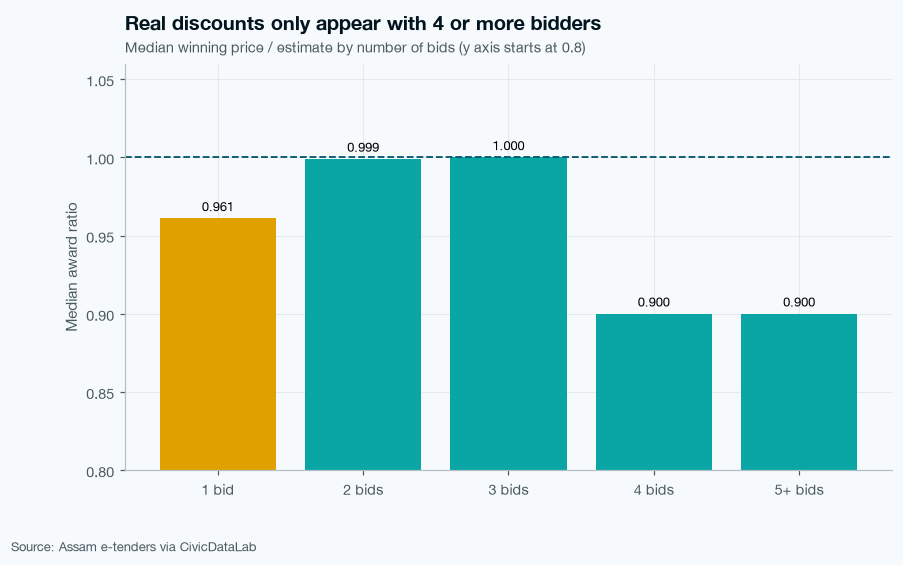

In [36]:
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
colors = [ts.SINGLE, ts.MULTI, ts.MULTI, ts.MULTI, ts.MULTI]  # single bid amber, others teal
bars = ax.bar(price_table.index, price_table["median_ratio"], color=colors)  # median ratio per bid group
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8.5)  # value on each bar
ax.axhline(1.0, color=ts.THIRD, linestyle="--", linewidth=1.2)  # paid the full estimate

# labels and finish
ax.set_ylabel("Median award ratio")  # y axis label
ax.set_ylim(0.8, 1.06)  # zoom in so small gaps are visible
subtitle = "Median winning price / estimate by number of bids (y axis starts at 0.8)"  # what is measured
ts.title(ax, "Real discounts only appear with 4 or more bidders", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8i_competition_price.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 13

- The price does not fall smoothly as bidders grow.
- With 2 or 3 bids, the middle award ratio is about 1.000. That means many of these works were given at the full estimate. 38.3% of 2-bid and 53.0% of 3-bid awards were almost exactly at the estimate.
- Real discounts only appear with 4 or more bids: the middle ratio drops to 0.900, and only 4.3% of 5+ bid awards were at the estimate.
- Single-bid tenders (0.961) sit in between. That looks odd, but it can happen when some tender rules fix the price close to the estimate.
- What I take away: competition clearly lowers the price only when it is strong (4+ bidders). A second bidder alone does not seem to bring the price down.

### Step 14 · What might one bidder cost, in rupees?

Here I turn the price gap into a rough rupee number. I take the money in single-bid awarded tenders and multiply it by two gaps:

- a careful gap: single-bid median minus the multi-bid median (from Step 12)
- a bigger gap: single-bid median minus the 5+ bids median (from Step 13), as if these tenders had strong competition

This is only a rough sign of what competition could save. It is not proof of any loss, because single-bid works may simply be harder or more remote.

In [37]:
single_awarded = awarded[(awarded["single_bid"] == 1) & (awarded["giant_value"] == False)]  # single-bid tenders with a clean award ratio
single_awarded_crore = single_awarded["estimated_value"].sum() / 10000000  # their estimated value in crore
med_strong = awarded.loc[awarded["bid_group"] == 5, "award_ratio"].median()  # median ratio with 5+ bids
gap_careful = med_single - med_multi  # careful gap
gap_strong = med_single - med_strong  # bigger gap
cost_careful = gap_careful * single_awarded_crore  # careful rupee estimate
cost_strong = gap_strong * single_awarded_crore  # bigger rupee estimate

In [38]:
print("Single-bid awarded tenders used:", len(single_awarded), "| value: Rs", round(single_awarded_crore), "crore")  # base money
print("Careful gap:", round(gap_careful * 100, 1), "% of the estimate -> about Rs", round(cost_careful), "crore")  # careful estimate
print("Bigger gap:", round(gap_strong * 100, 1), "% of the estimate -> about Rs", round(cost_strong), "crore")  # bigger estimate
cost_rows = []  # rows for the saved table
row = {}  # careful row
row["view"] = "single vs multi"  # which gap
row["gap_pct"] = gap_careful * 100  # gap in percent
row["rs_crore"] = cost_careful  # rupees
cost_rows.append(row)  # keep it
row = {}  # bigger row
row["view"] = "single vs 5+ bids"  # which gap
row["gap_pct"] = gap_strong * 100  # gap in percent
row["rs_crore"] = cost_strong  # rupees
cost_rows.append(row)  # keep it
cost_table = pd.DataFrame(cost_rows)  # make a table
cost_table.to_csv(rep_dir + "/s8_cost_of_one_bidder.csv", index=False)  # save it

Single-bid awarded tenders used: 1481 | value: Rs 11224 crore
Careful gap: 1.1 % of the estimate -> about Rs 120 crore
Bigger gap: 6.1 % of the estimate -> about Rs 681 crore


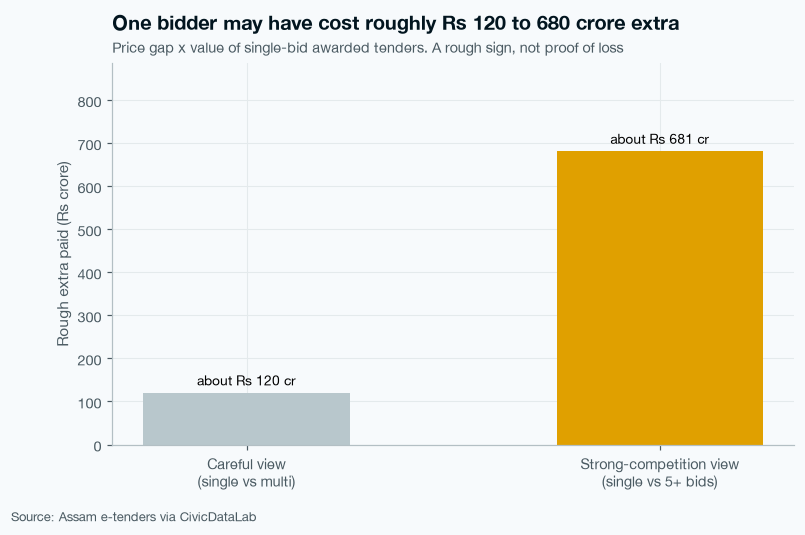

In [39]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # one chart
names = ["Careful view\n(single vs multi)", "Strong-competition view\n(single vs 5+ bids)"]  # bar names
bars = ax.bar(names, cost_table["rs_crore"], color=[ts.NEUTRAL, ts.SINGLE], width=0.5)  # two bars
bar_text = []  # labels
for i in range(len(cost_table)):  # one label per bar
    bar_text.append("about Rs " + str(int(round(cost_table["rs_crore"].iloc[i]))) + " cr")  # rupee label
ax.bar_label(bars, labels=bar_text, padding=3, fontsize=9)  # write labels

# labels and finish
ax.set_ylabel("Rough extra paid (Rs crore)")  # y axis label
ax.set_ylim(0, cost_table["rs_crore"].max() * 1.3)  # headroom
subtitle = "Price gap x value of single-bid awarded tenders. A rough sign, not proof of loss"  # what is measured
ts.title(ax, "One bidder may have cost roughly Rs 120 to 680 crore extra", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8j_cost_of_one_bidder.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 14

- Single-bid awarded tenders with a clean ratio are worth about Rs 11,224 crore.
- With the careful gap (1.1% of the estimate), one bidder may have cost about Rs 120 crore extra.
- With the bigger gap (6.1%, as if these tenders had 5+ bidders), it may have cost about Rs 681 crore.
- So my rough range is Rs 120 to 680 crore. I call it a rough sign, not proof of loss. Single-bid works may be harder, smaller or more remote, and the price gap was not the same in every period (Step 12).
- For slides this gives a business meaning: getting more bidders could save the state real money, and that is why it is worth flagging single-bid risk early.

### Step 15 · Do a few firms win most of the work?

Here I look at the winners of awarded tenders. Firm names are real people and businesses, so I hide them. I give each firm a code: S1 is the firm with the most wins, S2 the next, and so on. Before that I tidy the names a little (small letters, no "M/S", no dots), so the same firm written two ways counts once.

Then I measure how spread out the winning is in each department with the HHI score.

| Part | Simple meaning |
|---|---|
| HHI | A 0 to 10,000 score of how much the wins are held by a few firms |
| Low HHI (below 1,500) | Wins are spread over many firms |
| High HHI (above 2,500) | A few firms win most of the work |
| How it is made | Take each firm's share of wins in %, square it, add them up |

In [40]:
winners = base[base["winning_supplier"].notna()].copy()  # tenders with a known winner
winners["clean_name"] = winners["winning_supplier"].str.lower()  # small letters
winners["clean_name"] = winners["clean_name"].str.replace("m/s.", "", regex=False)  # remove "m/s."
winners["clean_name"] = winners["clean_name"].str.replace("m/s", "", regex=False)  # remove "m/s"
winners["clean_name"] = winners["clean_name"].str.replace(".", "", regex=False)  # remove dots
winners["clean_name"] = winners["clean_name"].str.strip()  # remove spaces at the ends

In [41]:
win_counts = winners["clean_name"].value_counts()  # wins per firm, most first
codes = pd.DataFrame({"clean_name": win_counts.index, "wins": win_counts.values})  # one row per firm
codes["code"] = "S" + pd.Series(range(1, len(codes) + 1)).astype(str)  # S1, S2, S3 ...
winners = winners.merge(codes[["clean_name", "code"]], on="clean_name", how="left")  # add the code to each award
top10_share = codes["wins"].head(10).sum() / codes["wins"].sum() * 100  # share of wins taken by the top 10 firms
print("Awards with a winner:", len(winners), "| different firms:", len(codes))  # size
print("Top 10 firms won", round(top10_share, 1), "% of all awards")  # concentration overall

Awards with a winner: 3610 | different firms: 1996
Top 10 firms won 4.7 % of all awards


In [42]:
dept_awards = winners["dept_main"].value_counts()  # awards per department
big_depts = dept_awards[dept_awards >= 30].index  # departments with at least 30 awards
hhi_rows = []  # one row per department
for dept in big_depts:  # one department at a time
    shares = winners.loc[winners["dept_main"] == dept, "code"].value_counts(normalize=True) * 100  # each firm's share of wins in %
    row = {}  # new row
    row["department"] = dept  # department name
    row["awards"] = dept_awards[dept]  # number of awards
    row["firms"] = len(shares)  # number of different winners
    row["top_firm_share"] = shares.iloc[0]  # share of the biggest winner
    row["hhi"] = (shares ** 2).sum()  # HHI score
    hhi_rows.append(row)  # keep the row
hhi_table = pd.DataFrame(hhi_rows).sort_values("hhi", ascending=False).round(1)  # most concentrated first
hhi_table.to_csv(rep_dir + "/s8_supplier_hhi.csv", index=False)  # save the table
hhi_table  # show it

,department,awards,firms,top_firm_share,hhi
7,Food Civil Supplies and Consumer Affairs Depar...,127,28,28.3,1210.9
19,Assam Agricultural University,32,18,18.8,839.8
14,Pr. Chief Conservator of Forest and Head of Fo...,61,35,16.4,561.7
17,Guwahati Municipal Corporation,44,28,9.1,464.9
13,Home B,65,34,7.7,433.1
5,Assam Power Distribution Company Ltd,130,49,9.2,432.0
16,Animal Husbandry and Veterinary Department,47,34,10.6,412.0
15,Principal Secretary- P and RD- Assam Secretariat,50,36,12.0,400.0
20,Cooperation Department,30,28,6.7,377.8
8,Welfare of Plain Tribes and Backward Classes,124,67,12.9,340.8


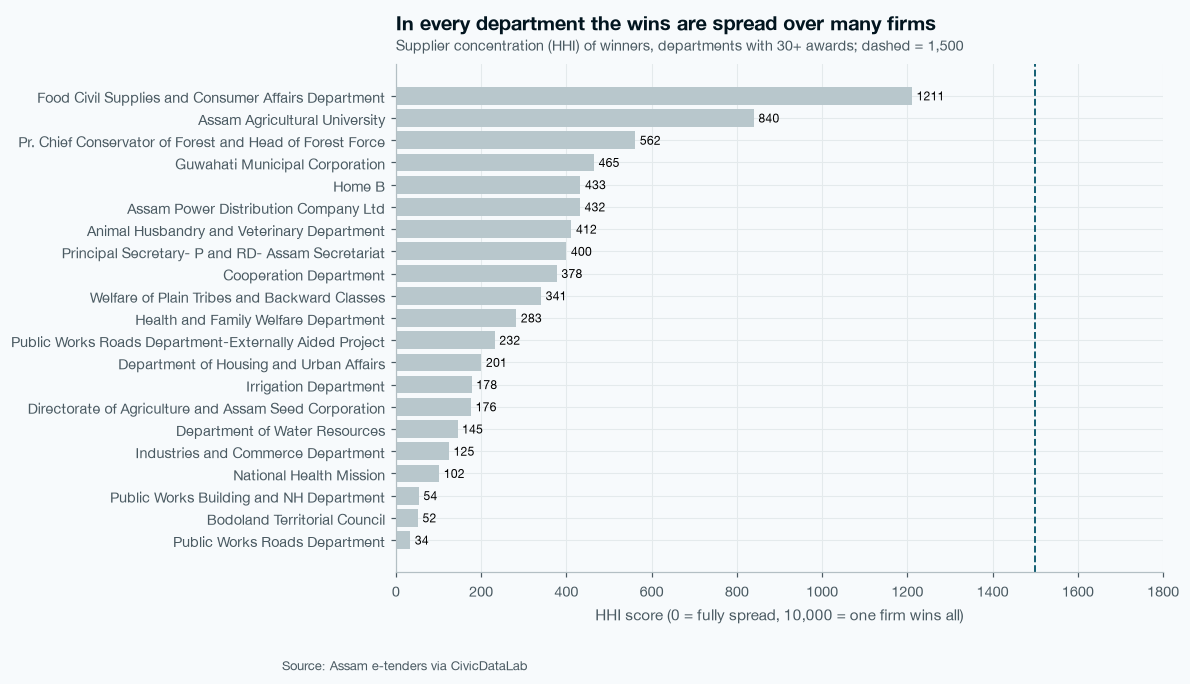

In [43]:
fig, ax = plt.subplots(figsize=(9, 6))  # one chart
colors = np.where(hhi_table["hhi"] >= 1500, ts.THIRD, ts.NEUTRAL)  # dark if above the 1,500 line
bars = ax.barh(hhi_table["department"], hhi_table["hhi"], color=colors)  # one bar per department
ax.invert_yaxis()  # most concentrated at the top
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)  # HHI on each bar
ax.axvline(1500, color=ts.THIRD, linestyle="--", linewidth=1.2)  # line where concentration starts

# labels and finish
ax.set_xlabel("HHI score (0 = fully spread, 10,000 = one firm wins all)")  # x axis label
ax.set_xlim(0, max(hhi_table["hhi"].max() * 1.2, 1800))  # room for labels and the line
subtitle = "Supplier concentration (HHI) of winners, departments with 30+ awards; dashed = 1,500"  # what is measured
ts.title(ax, "In every department the wins are spread over many firms", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8k_supplier_hhi.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 15

- 3,610 awards have a winner, spread over 1,996 different firms (after tidying the names). The names are hidden as S1, S2 and so on.
- The top 10 firms won only 4.7% of all awards, so no small group controls the whole state.
- Inside departments, the HHI is below 1,500 everywhere, so in every department the wins are spread over many firms.
- The most concentrated is Food Civil Supplies and Consumer Affairs (HHI 1,211), where the biggest winner took 28.3% of awards. It is the closest to the warning line, but still below it.
- The big works departments (PWD Roads, PWD Building, BTC) are the most spread out (HHI around 34-54), because they have hundreds of different winners.

### Step 16 · Do the same firms keep winning the one-bidder tenders?

A firm winning many single-bid tenders could be a warning sign, or just a firm that works in remote places nobody else goes to. Here I count how much of the single-bid work goes to "repeat winners" (firms with 3 or more wins in that group), and I compare it with the multi-bid work.

In [44]:
single_wins = winners[winners["single_bid"] == 1]  # awards from single-bid tenders
multi_wins = winners[winners["single_bid"] == 0]  # awards from multi-bid tenders
single_counts = single_wins["code"].value_counts()  # wins per firm, single-bid
multi_counts = multi_wins["code"].value_counts()  # wins per firm, multi-bid
single_repeat_share = single_counts[single_counts >= 3].sum() / len(single_wins) * 100  # share won by repeat winners, single-bid
multi_repeat_share = multi_counts[multi_counts >= 3].sum() / len(multi_wins) * 100  # share won by repeat winners, multi-bid

In [45]:
print("Single-bid awards:", len(single_wins), "| firms:", len(single_counts), "| repeat winners take", round(single_repeat_share, 1), "%")  # single-bid view
print("Multi-bid awards:", len(multi_wins), "| firms:", len(multi_counts), "| repeat winners take", round(multi_repeat_share, 1), "%")  # multi-bid view
repeat_rows = []  # rows for the saved table
row = {}  # single-bid row
row["group"] = "single bid"  # label
row["awards"] = len(single_wins)  # awards
row["firms"] = len(single_counts)  # firms
row["repeat_winner_share"] = single_repeat_share  # share
repeat_rows.append(row)  # keep it
row = {}  # multi-bid row
row["group"] = "multi bid"  # label
row["awards"] = len(multi_wins)  # awards
row["firms"] = len(multi_counts)  # firms
row["repeat_winner_share"] = multi_repeat_share  # share
repeat_rows.append(row)  # keep it
pd.DataFrame(repeat_rows).to_csv(rep_dir + "/s8_repeat_winners.csv", index=False)  # save it

Single-bid awards: 1765 | firms: 1049 | repeat winners take 37.8 %
Multi-bid awards: 1845 | firms: 1277 | repeat winners take 26.2 %


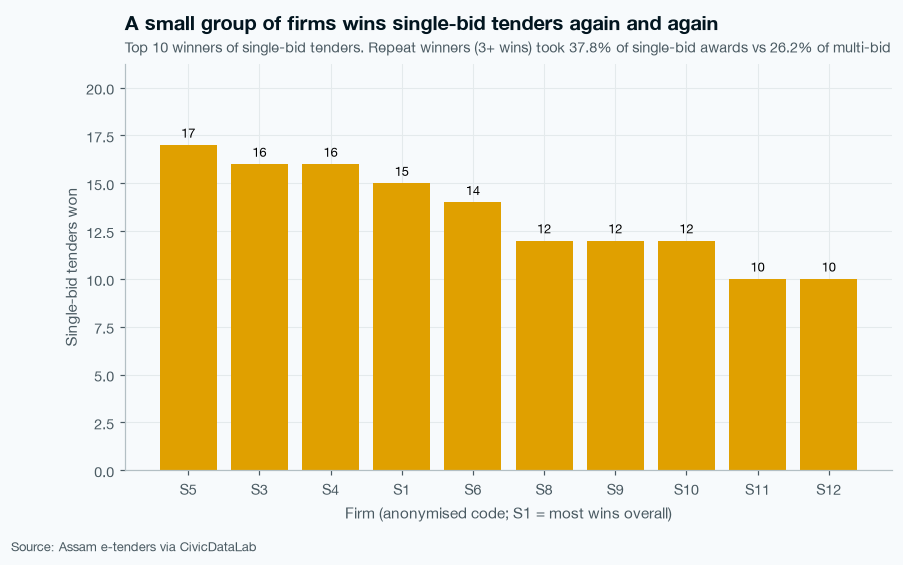

In [46]:
top_single = single_counts.head(10)  # 10 firms with the most single-bid wins
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
bars = ax.bar(top_single.index, top_single.values, color=ts.SINGLE)  # wins per firm
ax.bar_label(bars, padding=3, fontsize=8.5)  # count on each bar

# labels and finish
ax.set_ylabel("Single-bid tenders won")  # y axis label
ax.set_xlabel("Firm (anonymised code; S1 = most wins overall)")  # x axis label
ax.set_ylim(0, top_single.max() * 1.25)  # headroom
subtitle = "Top 10 winners of single-bid tenders. Repeat winners (3+ wins) took " + str(round(single_repeat_share, 1)) + "% of single-bid awards vs " + str(round(multi_repeat_share, 1)) + "% of multi-bid"  # what is measured
ts.title(ax, "A small group of firms wins single-bid tenders again and again", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8l_repeat_winners.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 16

- Single-bid awards: 1,765 awards to 1,049 firms. Multi-bid awards: 1,845 awards to 1,277 firms.
- Firms with 3 or more wins took 37.8% of single-bid awards, but only 26.2% of multi-bid awards.
- So the same firms come back more often when there is no competition. The top single-bid winners (like S5, S3, S4) each won 16-17 single-bid tenders.
- This does not prove anything wrong. A firm may be the only one working in a remote area. But it is a useful follow-up check for an auditor: "who keeps winning the one-bidder tenders?".

### Step 17 · Do amendments change the number of bidders?

An amendment (also called a corrigendum) is a change made to a tender after it is published, for example a new closing date. My guess was that tenders changed many times confuse bidders. Here I check the single-bid rate for 0, 1, 2 and 3-or-more amendments, and I use a chi-square test to see if the gaps are real.

| Part | Simple meaning |
|---|---|
| Amendment | A change made to a tender after publishing |
| Chi-square test | Checks if the single-bid share really differs between groups, or only by chance |
| p-value below 0.05 | The gaps are probably real |

In [47]:
base["amend_group"] = base["amendment_count"].clip(upper=3)  # 3 or more amendments all become 3
amend_table = pd.crosstab(base["amend_group"], base["single_bid"])  # counts of single and multi bids per group
chi_result = chi2_contingency(amend_table)  # test the whole table
amend_rate = base.groupby("amend_group")["single_bid"].agg(["count", "mean"])  # tenders and rate per group
amend_rate["mean"] = (amend_rate["mean"] * 100).round(1)  # rate in percent
amend_rate.index = ["0", "1", "2", "3+"]  # friendly names
print("Chi-square p-value (all periods together):", chi_result[1])  # below 0.05 = probably real
amend_rate  # show it

Chi-square p-value (all periods together): 1.9727660020443382e-05


,count,mean
0,4301,32.0
1,1823,26.7
2,508,25.0
3+,158,32.9


Again I check inside each period, because a whole-data gap can come from mixing old and new tenders.

In [48]:
amend_by_period = base.pivot_table(index="amend_group", columns="split", values="single_bid", aggfunc="mean") * 100  # rate per group and period
amend_by_period = amend_by_period[order].round(1)  # periods in time order
amend_by_period.index = ["0", "1", "2", "3+"]  # friendly names
amend_by_period.to_csv(rep_dir + "/s8_amendments.csv")  # save the table
amend_by_period  # show it

split,train,val,test
0,41.1,30.1,23.6
1,28.0,24.7,26.4
2,34.7,9.2,17.1
3+,35.6,44.4,13.3


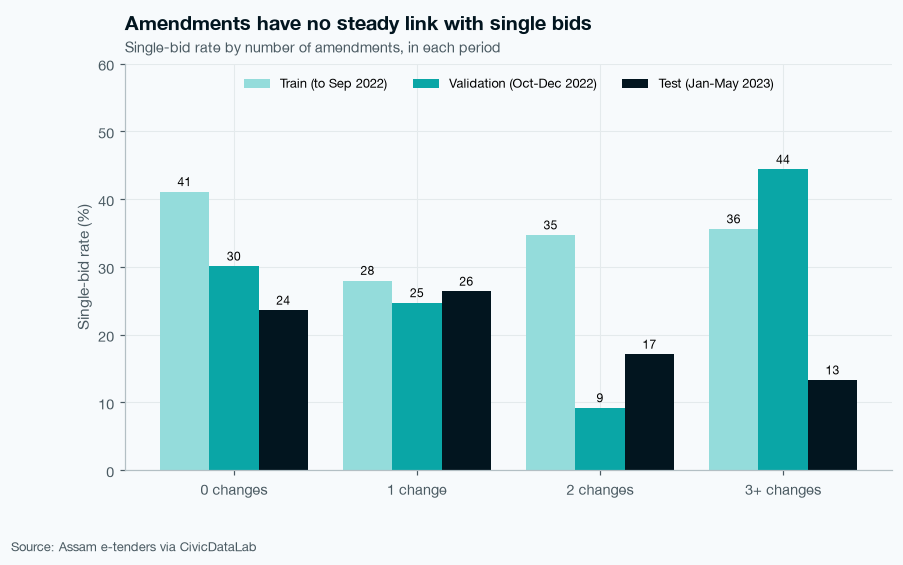

In [49]:
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
x = np.arange(len(amend_by_period))  # one position per amendment group
width = 0.27  # bar width
for i, p in enumerate(order):  # one set of bars per period
    bars = ax.bar(x + (i - 1) * width, amend_by_period[p], width, color=period_colors[i], label=period_name[p])  # bars for this period
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8)  # rate on each bar

# labels and finish
ax.set_xticks(x)  # ticks under each group
ax.set_xticklabels(["0 changes", "1 change", "2 changes", "3+ changes"])  # group names
ax.set_ylabel("Single-bid rate (%)")  # y axis label
ax.set_ylim(0, 60)  # headroom
ax.legend(loc="upper center", ncol=3, fontsize=8.5)  # legend in one row
subtitle = "Single-bid rate by number of amendments, in each period"  # what is measured
ts.title(ax, "Amendments have no steady link with single bids", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8m_amendments.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 17

- On the whole data, the chi-square p-value is very small (about 0.00002), so the single-bid rate does differ between amendment groups: 32.0% for 0 changes, 26.7% for 1, 25.0% for 2 and 32.9% for 3+.
- But inside each period the pattern jumps around. For 3+ changes the rate is 35.6% in train, 44.4% in validation and 13.3% in test. For 2 changes it is 34.7%, then 9.2%, then 17.1%.
- So the "real" whole-data gap mostly comes from mixing old and new tenders. It is my S5 lesson again: always check inside each period.
- My conclusion: amendments have no steady link with single bids. They also happen after publishing, so they were never going to be model inputs.

### Step 18 · Does re-posting a tender bring more bidders?

When a tender gets a poor response, an office often posts the same work again. Does the second try attract more firms? Here I find labelled tenders with the same cleaned title (title_key from S2) published on two or more different days. I number the attempts by date (1st, 2nd, 3rd or later) and compare their single-bid rates.

One limit: two tenders with the same short title may sometimes be two different works (for example "Supply of medicines"). So this is a rough check.

In [50]:
rp = base.sort_values("published_date").copy()  # tenders in date order
rp["day"] = rp["published_date"].dt.normalize()  # date without the time
rp["days_seen"] = rp.groupby("title_key")["day"].transform("nunique")  # on how many different days this title appeared
rp["attempt"] = rp.groupby("title_key")["day"].rank(method="dense")  # 1 = first day, 2 = second day ...
repost = rp[rp["days_seen"] >= 2].copy()  # only titles posted on 2 or more days
repost["attempt_group"] = repost["attempt"].clip(upper=3)  # 3rd or later become 3

In [51]:
repost_table = repost.groupby("attempt_group")["single_bid"].agg(["count", "mean"])  # tenders and rate per attempt
repost_table["mean"] = (repost_table["mean"] * 100).round(1)  # rate in percent
repost_table.index = ["1st attempt", "2nd attempt", "3rd or later"]  # friendly names
repost_table.columns = ["tenders", "single_rate"]  # friendly column names
repost_table.to_csv(rep_dir + "/s8_reposting.csv")  # save the table
print("Titles posted on 2+ days:", repost["title_key"].nunique(), "| tenders:", len(repost))  # size of the check
repost_table  # show it

Titles posted on 2+ days: 200 | tenders: 507


,tenders,single_rate
1st attempt,255,19.2
2nd attempt,222,33.3
3rd or later,30,30.0


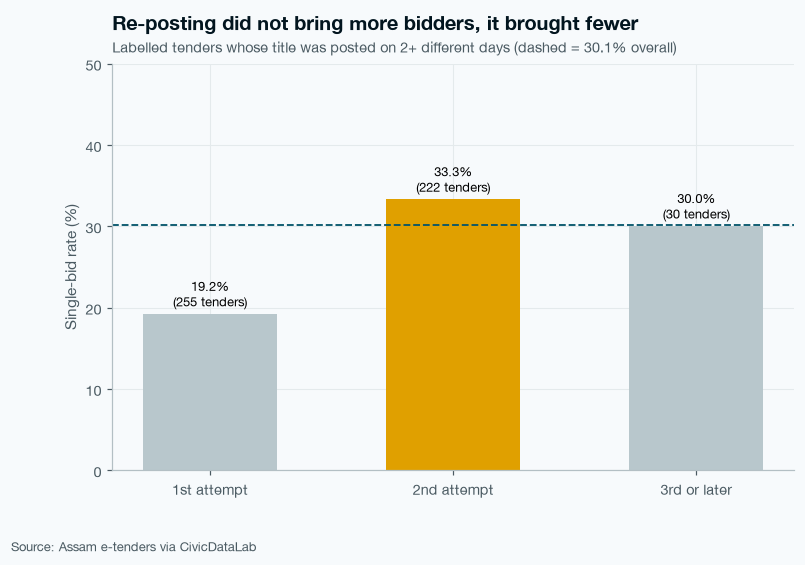

In [52]:
fig, ax = plt.subplots(figsize=(8, 4.8))  # one chart
colors = np.where(repost_table["single_rate"] > overall_rate, ts.SINGLE, ts.NEUTRAL)  # amber if above 30.1%
bars = ax.bar(repost_table.index, repost_table["single_rate"], color=colors, width=0.55)  # rate per attempt
bar_text = []  # labels
for i in range(len(repost_table)):  # one label per bar
    bar_text.append(str(repost_table["single_rate"].iloc[i]) + "%\n(" + str(repost_table["tenders"].iloc[i]) + " tenders)")  # rate and size
ax.bar_label(bars, labels=bar_text, padding=3, fontsize=8.5)  # write labels
ax.axhline(overall_rate, color=ts.THIRD, linestyle="--", linewidth=1.2)  # overall line

# labels and finish
ax.set_ylabel("Single-bid rate (%)")  # y axis label
ax.set_ylim(0, 50)  # headroom
subtitle = "Labelled tenders whose title was posted on 2+ different days (dashed = 30.1% overall)"  # what is measured
ts.title(ax, "Re-posting did not bring more bidders, it brought fewer", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8n_reposting.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 18

- I found 200 titles posted on two or more different days, covering 507 labelled tenders.
- First attempts got a single bid 19.2% of the time. Second attempts got a single bid 33.3% of the time, and third or later attempts 30.0%.
- So re-posting did not bring more bidders. The second try was more often a one-bidder tender.
- One possible reason: if no good firm came the first time, the same one interested firm may be the only one who comes back.
- Limit: two tenders with the same short title may sometimes be different works, so this is a rough check. It matches S3, where re-tenders within 60 days had the highest single-bid rate (40.0%).

## Part E · Isolation Forest, my second signal

### Step 19 · Train the "odd one out" detector

My S7 model answers "might this tender get only one bid?". The Isolation Forest answers a different question: "does this tender look strange compared with the rest?". Strange does not mean wrong. It just means worth a second look.

It only uses facts known on publishing day, so the app can use it for a brand-new tender. I use my 7 main clues plus 3 extra numbers from S5 (EMD ratio, tender fee and work period). Missing values were already filled with training medians in S5. I learn only from the training tenders, then score validation and test.

| Part | Simple meaning |
|---|---|
| Isolation Forest | Builds many random trees that keep splitting the tenders. An odd tender gets separated after only a few splits |
| Anomaly score | Higher = easier to separate = more unusual |
| Top 5% cut-off | The score above which only 5% of training tenders sit. Tenders above it get the "unusual" flag |
| random_state=42 | Fixes the randomness so I get the same result every run |

In [53]:
iso_clues = ["dept_rate", "log_value", "value_missing", "bid_window_days", "months_to_fy_end", "same_day_lot", "retender_60d"]  # my 7 main clues
iso_clues = iso_clues + ["emd_ratio", "log_fee", "work_period_days"]  # 3 extra publish-day numbers from S5
X_all = feats[iso_clues]  # clues for all labelled tenders
X_train = feats.loc[feats["split"] == "train", iso_clues]  # clues for training tenders only
print("Training tenders:", len(X_train), "| clues:", len(iso_clues))  # size check
print("Missing values:", X_all.isna().sum().sum())  # should be 0

Training tenders: 2753 | clues: 10
Missing values: 0


In [54]:
iso = IsolationForest(n_estimators=500, random_state=42)  # 500 random trees, fixed randomness
iso.fit(X_train)  # learn what normal tenders look like, from training only
scores = -iso.score_samples(X_all)  # anomaly score for every tender (minus sign so higher = odder)
train_scores = scores[feats["split"] == "train"]  # scores of training tenders
cutoff = np.quantile(train_scores, 0.95)  # score above which the oddest 5% of training tenders sit
print("Top 5% cut-off score:", round(cutoff, 4))  # the line for the flag

Top 5% cut-off score: 0.5462


In [55]:
anom = feats[["tender_id", "split", "single_bid"]].copy()  # small table for the anomaly results
anom["anomaly_score"] = scores  # add the score
anom["unusual"] = (anom["anomaly_score"] >= cutoff).astype(int)  # 1 if in the odd zone
flag_table = anom.groupby("split")["unusual"].agg(["count", "sum", "mean"]).reindex(order)  # flagged tenders per period
flag_table["mean"] = (flag_table["mean"] * 100).round(1)  # share flagged in percent
flag_table.columns = ["tenders", "flagged", "flagged_pct"]  # friendly names
flag_table  # show it

,tenders,flagged,flagged_pct
split,,,
train,2753,138,5.0
val,2270,35,1.5
test,1767,74,4.2


### Step 20 · Is the flag stable if I change the randomness?

The trees are random. If a different random_state gave me a totally different list of unusual tenders, I could not trust the flag. Here I train 5 more detectors with other random_state values and check how many of my flagged test tenders they also flag.

In [56]:
main_flag = anom["unusual"].values  # flags from my main detector
test_mask = (anom["split"] == "test").values  # True for test tenders
main_test_flags = main_flag[test_mask]  # main flags on test
seed_rows = []  # one row per extra detector
for seed in [1, 2, 3, 4, 5]:  # five other random settings
    other = IsolationForest(n_estimators=500, random_state=seed).fit(X_train)  # train another detector
    other_scores = -other.score_samples(X_all)  # its scores
    other_cut = np.quantile(other_scores[feats["split"] == "train"], 0.95)  # its own top 5% line
    other_test_flags = (other_scores[test_mask] >= other_cut).astype(int)  # its flags on test
    both = ((main_test_flags == 1) & (other_test_flags == 1)).sum()  # flagged by both
    row = {}  # new row
    row["random_state"] = seed  # which setting
    row["test_flagged"] = other_test_flags.sum()  # how many it flagged
    row["also_in_main"] = both / main_test_flags.sum() * 100  # share of my main flags it agrees with
    seed_rows.append(row)  # keep it
seed_table = pd.DataFrame(seed_rows).round(1)  # make a table
print("Main detector flagged on test:", main_test_flags.sum())  # my main count
seed_table  # show it

Main detector flagged on test: 74


,random_state,test_flagged,also_in_main
0,1,78,83.8
1,2,80,93.2
2,3,73,86.5
3,4,85,83.8
4,5,76,89.2


### Insight · Steps 19 and 20

- The detector learned from 2,753 training tenders and 10 publish-day clues, with no missing values.
- By design it flagged 5.0% of training tenders (138). It flagged only 1.5% of validation tenders (35) and 4.2% of test tenders (74).
- Validation has fewer flags. A possible reason is the big December 2022 batch of similar road tenders (seen in S6): when many tenders look alike, fewer of them stand out.
- The flag is stable. Five other random settings flagged 73-85 test tenders, and each agreed with 84-93% of my main flags. So the list does not depend on luck.

### Step 21 · Why do the top 3 test tenders look odd?

A flag is only useful if I can explain it. Here I take the 3 most unusual test tenders and find, for each one, the two clues that are furthest from a normal training tender. I measure "how far" in a fair way: the distance from the training median, divided by the normal spread of that clue (the middle 50% range). For yes/no clues that have no middle range, I use the standard deviation instead.

These examples will also feed the GenAI brief in S10.

In [57]:
med = X_train.median()  # normal value of each clue
spread = X_train.quantile(0.75) - X_train.quantile(0.25)  # normal spread (middle 50% range)
spread = spread.replace(0, np.nan)  # a spread of 0 cannot be used
spread = spread.fillna(X_train.std())  # use the standard deviation instead
test_anom = anom[anom["split"] == "test"].sort_values("anomaly_score", ascending=False)  # test tenders, oddest first
top3 = test_anom.head(3)  # the 3 oddest

In [58]:
example_rows = []  # one row per example
for tid in top3["tender_id"]:  # one tender at a time
    values = feats.loc[feats["tender_id"] == tid, iso_clues].iloc[0]  # its clue values
    distance = ((values - med) / spread).abs()  # how far each clue is from normal
    distance = distance.sort_values(ascending=False)  # most unusual clue first
    top_clue = distance.index[0]  # the most unusual clue
    second_clue = distance.index[1]  # the second most unusual clue
    row = {}  # new row
    row["tender_id"] = tid  # tender
    row["title"] = base.loc[base["tender_id"] == tid, "title"].iloc[0][:90]  # first 90 letters of the title
    row["department"] = base.loc[base["tender_id"] == tid, "dept_main"].iloc[0]  # department
    row["odd_clue"] = top_clue  # most unusual clue
    row["its_value"] = round(values[top_clue], 3)  # value of that clue
    row["normal_value"] = round(med[top_clue], 3)  # training median of that clue
    row["odd_clue_2"] = second_clue  # second most unusual clue
    row["its_value_2"] = round(values[second_clue], 3)  # value of the second clue
    row["normal_value_2"] = round(med[second_clue], 3)  # training median of the second clue
    row["single_bid"] = base.loc[base["tender_id"] == tid, "single_bid"].iloc[0]  # what really happened
    example_rows.append(row)  # keep it
examples = pd.DataFrame(example_rows)  # make a table
examples.to_csv(rep_dir + "/s8_anomaly_examples.csv", index=False)  # save for the GenAI brief
examples  # show it

,tender_id,title,department,odd_clue,its_value,normal_value,odd_clue_2,its_value_2,normal_value_2,single_bid
0,2023_PWD_29083_2,CE/NEC/2022-23/01,Public Works Roads Department,same_day_lot,1.0,0.0,work_period_days,1085.0,180.000,0.0
1,2023_CD_29381_2,Mechanized Chaff Cutters,Cooperation Department,retender_60d,1.0,0.0,log_fee,0.0,7.465,0.0
2,2023_HFWD_29385_2,SUPPLY OF STATIONERY ITEMS ON RATE CONTRACT BA...,Health and Family Welfare Department,retender_60d,1.0,0.0,value_missing,1.0,0.000,0.0


### Insight · Step 21

- The 3 oddest test tenders were all odd mainly because of a rare yes/no clue (same_day_lot or retender_60d), plus one more unusual number.
- Tender 1 (PWD Roads) was part of a same-day lot and had a work period of 1,085 days, against a normal 180.
- Tender 2 (Cooperation Department, chaff cutters) was a quick re-tender and had no tender fee, against a normal fee level.
- Tender 3 (Health and Family Welfare, stationery) was a quick re-tender and had no written value.
- None of these 3 got a single bid. That is fine, because the flag means "this looks unusual", not "this will get one bid". The clue pairs give the GenAI brief real facts to explain in S10.

### Step 22 · Do the two signals find the same tenders?

Now I compare the "unusual" flag with my S7 risk band (High, Medium, Low) on the test tenders. I want to know how much the two signals overlap. A big overlap means they agree on a core group of tenders. A small overlap means each one finds different tenders. Both answers are useful, as long as I report them honestly.

In [59]:
both_signals = preds[["tender_id", "band", "estimated_value"]].merge(anom[["tender_id", "single_bid", "anomaly_score", "unusual"]], on="tender_id", how="left")  # test tenders with both signals
overlap = pd.crosstab(both_signals["band"], both_signals["unusual"])  # band vs flag counts
overlap = overlap.reindex(["High", "Medium", "Low"])  # bands in order
overlap.columns = ["not unusual", "unusual"]  # friendly names
overlap["unusual_pct"] = (overlap["unusual"] / (overlap["unusual"] + overlap["not unusual"]) * 100).round(1)  # share flagged in each band
high_and_unusual = overlap.loc["High", "unusual"]  # tenders flagged by both
all_unusual = overlap["unusual"].sum()  # all unusual test tenders
print("Unusual test tenders:", all_unusual, "| also in the High band:", high_and_unusual)  # overlap size
overlap.to_csv(rep_dir + "/s8_signal_overlap.csv")  # save the table
overlap  # show it

Unusual test tenders: 74 | also in the High band: 54


,not unusual,unusual,unusual_pct
band,,,
High,299,54,15.3
Medium,527,3,0.6
Low,867,17,1.9


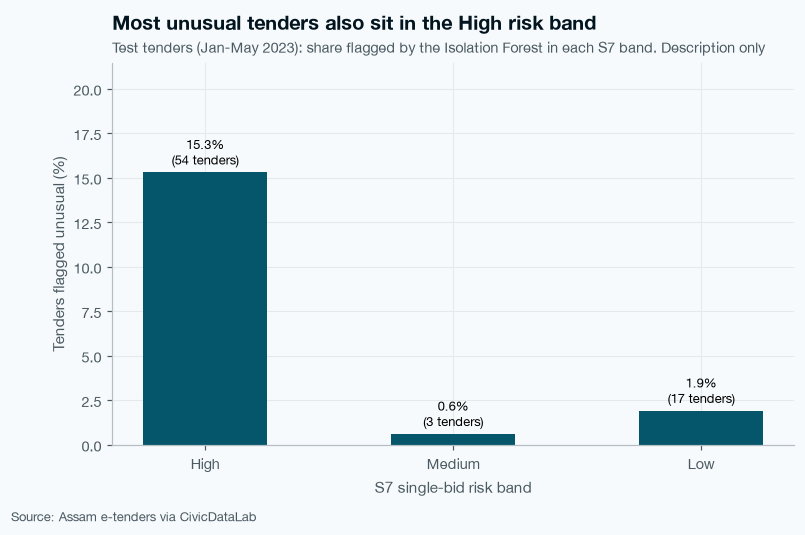

In [60]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # one chart
bars = ax.bar(overlap.index, overlap["unusual_pct"], color=ts.THIRD, width=0.5)  # share flagged unusual in each band
bar_text = []  # labels
for i in range(len(overlap)):  # one label per band
    bar_text.append(str(overlap["unusual_pct"].iloc[i]) + "%\n(" + str(overlap["unusual"].iloc[i]) + " tenders)")  # share and count
ax.bar_label(bars, labels=bar_text, padding=3, fontsize=8.5)  # write labels

# labels and finish
ax.set_xlabel("S7 single-bid risk band")  # x axis label
ax.set_ylabel("Tenders flagged unusual (%)")  # y axis label
ax.set_ylim(0, overlap["unusual_pct"].max() * 1.4)  # headroom
subtitle = "Test tenders (Jan-May 2023): share flagged by the Isolation Forest in each S7 band. Description only"  # what is measured
ts.title(ax, "Most unusual tenders also sit in the High risk band", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8o_signal_overlap.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 22

- On the test tenders, 54 of the 74 unusual tenders also sit in my High risk band. That is 73% of the unusual tenders.
- Looked at the other way, only 15.3% of High band tenders are unusual. The Medium and Low bands have almost none (0.6% and 1.9%).
- So the two signals overlap more than I expected. They agree on a core group of odd, high-risk tenders, and the flag picks out a small part of the High band.
- A likely reason: both signals are built from the same publish-day clues, so a tender with rare clue values can stand out in both.
- I report this honestly. The flag is still useful because it adds a reason ("this tender is odd because...") and it can point inside the High band to where an auditor should look first. In S7 these test answers were already open, so this is a description, not a new test.

### Step 23 · Do unusual tenders get single bids more often?

Here I check the single-bid rate of flagged and not-flagged tenders in each period. I will report the answer honestly either way. If unusual tenders are not more often single-bid, it simply means the flag is a different kind of signal: "look again, this one is odd", not "this one will get one bid".

In [61]:
flag_rate = anom.pivot_table(index="unusual", columns="split", values="single_bid", aggfunc="mean") * 100  # rate per flag and period
flag_rate = flag_rate[order].round(1)  # periods in time order
flag_rate.index = ["Not unusual", "Unusual"]  # friendly names
flag_n = anom.pivot_table(index="unusual", columns="split", values="single_bid", aggfunc="count")[order]  # tenders per cell
print(flag_n)  # how many tenders sit behind each rate
flag_rate  # show it

split    train   val  test
unusual                   
0         2615  2235  1693
1          138    35    74


split,train,val,test
Not unusual,36.1,27.5,23.6
Unusual,34.8,42.9,28.4


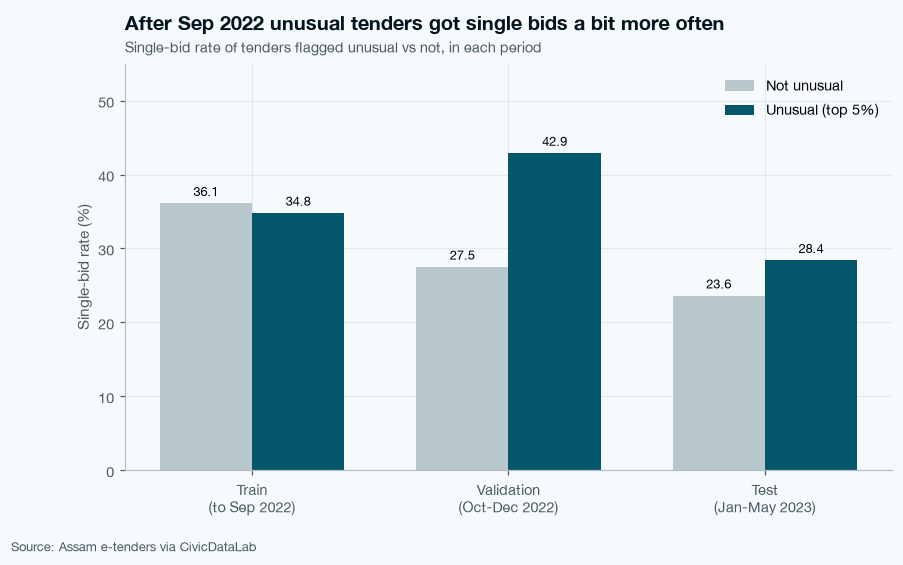

In [62]:
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
x = np.arange(len(order))  # one position per period
width = 0.36  # bar width
bars1 = ax.bar(x - width / 2, flag_rate.loc["Not unusual"], width, color=ts.NEUTRAL, label="Not unusual")  # normal tenders
bars2 = ax.bar(x + width / 2, flag_rate.loc["Unusual"], width, color=ts.THIRD, label="Unusual (top 5%)")  # flagged tenders
ax.bar_label(bars1, fmt="%.1f", padding=3, fontsize=8.5)  # labels
ax.bar_label(bars2, fmt="%.1f", padding=3, fontsize=8.5)  # labels

# labels and finish
period_labels = []  # x labels
for p in order:  # one label per period
    period_labels.append(period_name[p].replace(" (", "\n("))  # two-line label
ax.set_xticks(x)  # ticks
ax.set_xticklabels(period_labels)  # period names
ax.set_ylabel("Single-bid rate (%)")  # y axis label
ax.set_ylim(0, 55)  # headroom
ax.legend(loc="upper right")  # legend
subtitle = "Single-bid rate of tenders flagged unusual vs not, in each period"  # what is measured
ts.title(ax, "After Sep 2022 unusual tenders got single bids a bit more often", subtitle=subtitle)  # finding as title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8p_unusual_vs_single.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 23

- In train, unusual tenders got a single bid a little less often than normal ones (34.8% vs 36.1%).
- After Sep 2022 it flipped: unusual tenders got single bids more often, 42.9% vs 27.5% in validation and 28.4% vs 23.6% in test.
- The unusual groups are small (35 tenders in validation and 74 in test), so these rates can jump around.
- My honest reading: the flag is not a strong single-bid predictor on its own. But in the newer periods unusual tenders were somewhat more likely to get one bid, which supports showing the flag next to the risk band in the app.

Now I save the results. I save the scores for every labelled tender. For the app I also train one final detector on all 6,790 labelled tenders, the same way I made the final app model in S7, so the app knows the newest "normal". I save it with its clue list and its own top 5% cut-off.

In [63]:
anom.to_csv(rep_dir + "/s8_anomaly_scores.csv", index=False)  # scores and flags of all labelled tenders
app_iso = IsolationForest(n_estimators=500, random_state=42)  # same settings as before
app_iso.fit(X_all)  # learn from all labelled tenders, for the app
app_scores = -app_iso.score_samples(X_all)  # scores from the app detector
app_cutoff = np.quantile(app_scores, 0.95)  # its own top 5% line
joblib.dump(app_iso, model_dir + "/tenderlens_iforest.joblib")  # save the app detector

['../models/tenderlens_iforest.joblib']

In [64]:
iso_info = pd.DataFrame({"clue": iso_clues})  # clue list in the right order
iso_info.to_csv(model_dir + "/tenderlens_iforest_clues.csv", index=False)  # save the clue list
cut_rows = []  # cut-off table
row = {}  # one row
row["setting"] = "top_5pct_cutoff"  # name
row["value"] = app_cutoff  # value
cut_rows.append(row)  # keep it
pd.DataFrame(cut_rows).to_csv(model_dir + "/tenderlens_iforest_cutoff.csv", index=False)  # save the cut-off
print("App detector saved. Cut-off:", round(app_cutoff, 4))  # confirm

App detector saved. Cut-off: 0.5382


### Step 24 · A simple "check first" box for auditors

An auditor has limited time. Here I combine three things I already have into one simple rule. It is not a new model, just a rule anyone can follow:

- the S7 risk band (High, Medium or Low)
- the unusual flag from the Isolation Forest
- the size of the work: "big" means an estimated value of Rs 1 crore or more

| Priority | Rule |
|---|---|
| 1 Check first | High band AND (unusual OR big) |
| 2 Check next | High band only, or unusual only |
| 3 Routine | Everything else |

I show it on the test tenders only as a description, because the test answers are already open.

In [65]:
both_signals["big"] = (both_signals["estimated_value"] >= 10000000).astype(int)  # 1 if Rs 1 crore or more
both_signals["high"] = (both_signals["band"] == "High").astype(int)  # 1 if in the High band
p1 = (both_signals["high"] == 1) & ((both_signals["unusual"] == 1) | (both_signals["big"] == 1))  # priority 1 rule
p2 = ((both_signals["high"] == 1) | (both_signals["unusual"] == 1)) & (p1 == False)  # priority 2 rule
both_signals["priority"] = "3 Routine"  # start everyone as routine
both_signals.loc[p2, "priority"] = "2 Check next"  # mark priority 2
both_signals.loc[p1, "priority"] = "1 Check first"  # mark priority 1
both_signals["crore"] = both_signals["estimated_value"].fillna(0) / 10000000  # value in crore, empty as 0

In [66]:
box = both_signals.groupby("priority").agg(tenders=("tender_id", "count"), single_rate=("single_bid", "mean"), value_crore=("crore", "sum"))  # summary per priority
box["single_rate"] = (box["single_rate"] * 100).round(1)  # rate in percent
box["value_share"] = (box["value_crore"] / box["value_crore"].sum() * 100).round(1)  # share of all test money
box["value_crore"] = box["value_crore"].round(0)  # whole crores
box.to_csv(rep_dir + "/s8_check_first.csv")  # save the table
box  # show it

,tenders,single_rate,value_crore,value_share
priority,,,,
1 Check first,246,30.9,799.0,16.9
2 Check next,127,21.3,47.0,1.0
3 Routine,1394,22.8,3876.0,82.1


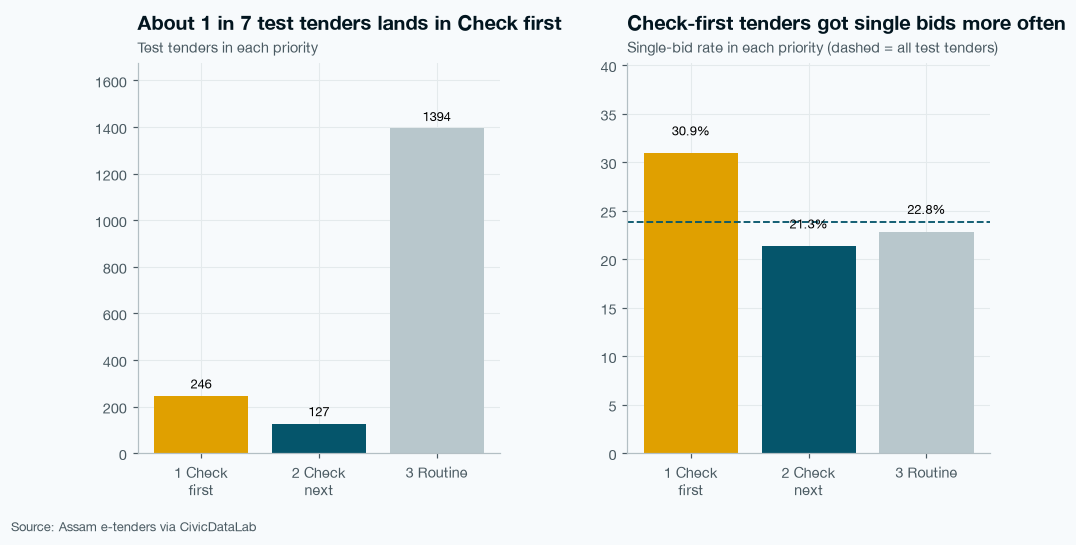

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))  # two charts side by side
fig.subplots_adjust(wspace=0.35)  # space between them
names = ["1 Check\nfirst", "2 Check\nnext", "3 Routine"]  # short names
colors = [ts.SINGLE, ts.THIRD, ts.NEUTRAL]  # one colour per priority

# left chart: number of tenders
ax = axes[0]  # left chart
bars = ax.bar(names, box["tenders"], color=colors)  # tenders per priority
ax.bar_label(bars, padding=3, fontsize=8.5)  # counts
ax.set_ylim(0, box["tenders"].max() * 1.2)  # headroom
ts.title(ax, "About 1 in 7 test tenders lands in Check first", subtitle="Test tenders in each priority")  # title

# right chart: single-bid rate
ax = axes[1]  # right chart
test_rate = both_signals["single_bid"].mean() * 100  # single-bid rate of all test tenders
bars = ax.bar(names, box["single_rate"], color=colors)  # single-bid rate per priority
ax.bar_label(bars, fmt="%.1f%%", padding=10, fontsize=8.5)  # rates, lifted to clear the dashed line
ax.axhline(test_rate, color=ts.THIRD, linestyle="--", linewidth=1.2)  # all test tenders line
ax.set_ylim(0, box["single_rate"].max() * 1.3)  # headroom
ts.title(ax, "Check-first tenders got single bids more often", subtitle="Single-bid rate in each priority (dashed = all test tenders)")  # title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S8q_check_first.png")  # save the chart
plt.show()  # show the chart

### Insight · Step 24

- On the test tenders, the simple rule puts 246 tenders (about 1 in 7) in "Check first", 127 in "Check next" and 1,394 in "Routine".
- Check-first tenders got a single bid 30.9% of the time, against 23.8% for all test tenders and 22.8% for Routine.
- Check-first tenders hold Rs 799 crore, 16.9% of the test money.
- Check next (High only or unusual only) did not do better than Routine (21.3%). So the band and the flag work best together with value size, not alone.
- This is a description on already-opened test answers, not a new fair test. But it gives the app a simple, explainable page: start with the short Check-first list.

## Part F · Close

### Step 25 · Did I miss anything?

Before I write my summary, I run a few small extra checks that came up while building this section:

1. Do unusual tenders carry more money than normal ones?
2. Do unusual tenders get a different award ratio?
3. Do unusual tenders get a different number of bids (not just one or more)?

In [68]:
check = base[["tender_id", "estimated_value", "award_ratio", "number_of_bids", "giant_value"]].merge(anom[["tender_id", "unusual"]], on="tender_id", how="left")  # small table for the checks
check = check[check["giant_value"] == False]  # leave out the 2 giant values
money_check = check.groupby("unusual")["estimated_value"].median() / 100000  # median value in lakh (1 lakh = 1,00,000)
ratio_check = check.groupby("unusual")["award_ratio"].median()  # median award ratio
bids_check = check.groupby("unusual")["number_of_bids"].median()  # median number of bids
extra = pd.DataFrame({"median_value_lakh": money_check, "median_award_ratio": ratio_check, "median_bids": bids_check}).round(3)  # one small table
extra.index = ["Not unusual", "Unusual"]  # friendly names
extra  # show it

,median_value_lakh,median_award_ratio,median_bids
Not unusual,94.275,0.950,3.0
Unusual,697.444,0.965,2.0


### Insight · Step 25

- Unusual tenders are much bigger works. Their middle value is about Rs 697 lakh (about Rs 7 crore), against about Rs 94 lakh for normal tenders.
- They also had a slightly smaller discount (middle award ratio 0.965 vs 0.950) and fewer bidders (middle 2 bids vs 3).
- So the odd tenders are often the big, expensive ones with less competition. That is exactly where an auditor's time is worth the most.

Things I checked and decided not to add:

- District map: checked in Step 11, too messy to place one in three tenders without guessing.
- K-Means groups: skipped for the whole project, because grouping tenders would not change which tender an auditor checks first. The Isolation Forest already gives me an unsupervised method with a clear job.
- Supplier network maps: they look fancy but would be hard to defend, and the names must stay hidden anyway.
- New prediction targets: S5 already showed that bid count and "1-2 bids" have no useful signal.

### Step 26 · Files saved in this section

Here I check that every file from this section was really saved.

In [69]:
saved = ["s8_bid_counts.csv", "s8_value_at_risk.csv", "s8_value_at_risk_dept.csv", "s8_dept_trend.csv", "s8_worktype_trend.csv"]  # tables, part 1
saved = saved + ["s8_march_rush.csv", "s8_award_ratio_test.csv", "s8_competition_price.csv", "s8_cost_of_one_bidder.csv"]  # part 2
saved = saved + ["s8_supplier_hhi.csv", "s8_repeat_winners.csv", "s8_amendments.csv", "s8_reposting.csv", "s8_anomaly_examples.csv"]  # part 3
saved = saved + ["s8_signal_overlap.csv", "s8_anomaly_scores.csv", "s8_check_first.csv"]  # part 4
for name in saved:  # check each table
    print(os.path.exists(rep_dir + "/" + name), name)  # True means saved

True s8_bid_counts.csv
True s8_value_at_risk.csv
True s8_value_at_risk_dept.csv
True s8_dept_trend.csv
True s8_worktype_trend.csv
True s8_march_rush.csv
True s8_award_ratio_test.csv
True s8_competition_price.csv
True s8_cost_of_one_bidder.csv
True s8_supplier_hhi.csv
True s8_repeat_winners.csv
True s8_amendments.csv
True s8_reposting.csv
True s8_anomaly_examples.csv
True s8_signal_overlap.csv
True s8_anomaly_scores.csv
True s8_check_first.csv


In [70]:
model_files = ["tenderlens_iforest.joblib", "tenderlens_iforest_clues.csv", "tenderlens_iforest_cutoff.csv"]  # app detector files
for name in model_files:  # check each model file
    print(os.path.exists(model_dir + "/" + name), name)  # True means saved
s8_charts = sorted(os.listdir(fig_dir))  # all chart files
s8_count = 0  # counter for S8 charts
for name in s8_charts:  # look at each chart file
    if name.startswith("S8"):  # only S8 charts
        s8_count = s8_count + 1  # count it
print("S8 charts saved:", s8_count)  # should be 17

True tenderlens_iforest.joblib
True tenderlens_iforest_clues.csv
True tenderlens_iforest_cutoff.csv
S8 charts saved: 17


## S8 Summary

Starting point
- After S7 I had a model that gives every new tender a risk band (High, Medium, Low), with a small but real win over random checking.
- My CP1 feedback said "more info can be gathered". So in S8 I stepped back to understand the problem in money, people and time, and I added a second signal.
- Test answers were already opened in S7, so every test number in S8 is a description, not a new fair test. Nothing in S8 changed my S7 model.

What I did
- Looked at the full spread of bids (1, 2, 3, 4+) in each period.
- Added up the rupees in single-bid tenders, by year and by department.
- Checked departments and work types before and after Sep 2022, who leaves the value empty, and how tenders spread over the financial year.
- Tried to use the district, and found the location column too messy.
- Studied after-bid facts only for understanding: award price vs number of bids, a rough cost of one bidder, supplier concentration (HHI, names hidden as S1, S2...), repeat winners, amendments and re-posting.
- Trained an Isolation Forest on publish-day clues (train only), flagged the oddest 5%, checked it with 5 other random settings, explained the top 3 tenders, and compared it with the S7 risk bands.
- Built a simple "check first" rule from risk band, unusual flag and value size.
- Saved an app version of the detector trained on all 6,790 labelled tenders.

What I found
- One-bid tenders shrank from 36.1% (train) to 27.8% (validation) to 23.8% (test). Most moved to 2 or 3 bids.
- About Rs 14,752 crore (36.5% of the money in tenders with a value) went out with only one bidder. Single-bid tenders are bigger works on average.
- The top 3 departments (APDCL, PWD Building and NH, PWD Roads EAP) hold 75.3% of the single-bid money.
- 13 of 15 departments got fewer single bids after Sep 2022. BTC got worse (24.7% to 39.9%), which explains my S7 miss on BTC.
- Every work type had fewer single bids in test than in train. Health fell the most (34.7% to 9.4%).
- An empty value field means fewer single bids in every period. It is mostly a habit of goods and supply tenders from a few offices.
- Tenders pile up in Nov-Dec. Single bids are less common from December to March, so months_to_fy_end is a calendar effect.
- Single-bid tenders got a slightly smaller discount (median 0.961 vs 0.950, p = 0.032), but not in every period. Real discounts only appear with 4+ bidders (median 0.900).
- A rough cost of one bidder is Rs 120 to 680 crore. It is a sign, not proof of loss.
- Wins are spread over many firms in every department (no HHI above 1,500). But repeat winners take 37.8% of single-bid awards vs 26.2% of multi-bid.
- Amendments have no steady link with single bids once I check inside each period.
- Re-posting did not help: second attempts got more single bids (33.3%) than first attempts (19.2%).
- The Isolation Forest flag is stable (84-93% agreement across random settings). 54 of its 74 unusual test tenders are also in the High band, so the two signals overlap more than I expected.
- After Sep 2022, unusual tenders got single bids a bit more often (42.9% vs 27.5% in validation, 28.4% vs 23.6% in test), but the groups are small.
- Unusual tenders are much bigger works (middle value about Rs 7 crore vs Rs 0.9 crore).
- The "check first" rule picks 246 test tenders (about 1 in 7). They got a single bid 30.9% of the time and hold 16.9% of the test money.
- District was checked and dropped: only 64.5% of tenders match a district name.

Files saved
- Tables in reports: s8_bid_counts, s8_value_at_risk, s8_value_at_risk_dept, s8_dept_trend, s8_worktype_trend, s8_march_rush, s8_award_ratio_test, s8_competition_price, s8_cost_of_one_bidder, s8_supplier_hhi, s8_repeat_winners, s8_amendments, s8_reposting, s8_anomaly_examples, s8_signal_overlap, s8_anomaly_scores, s8_check_first (all .csv).
- Models for the app: models/tenderlens_iforest.joblib, tenderlens_iforest_clues.csv, tenderlens_iforest_cutoff.csv.
- 17 charts in reports/figures: S8a to S8q.

Next steps
- S9: build an ANN on the same 7 clues and split, compare it fairly with LogReg and random on validation first, and report any test score only as extra.
- S10: show the unusual flag and its two odd clues next to the risk band in the app, add the "check first" page, and use s8_anomaly_examples.csv in the GenAI brief.
- For the slides: the Rs 14,752 crore money line (S8b), the BTC trend (S8d) and the "check first" box (S8q).